# Processamento dos Dados Experimentais

## Plataforma de Identificação Térmica e Controlo Preditivo

Este notebook executa a metodologia de processamento dos dados experimentais utilizados na identificação de um modelo térmico **2R2C** e no posterior desenvolvimento de um sistema de **Controlo Preditivo Baseado em Modelo — MPC**.

O processamento é realizado através dos módulos reutilizáveis disponíveis na pasta `Codigos`, mantendo o notebook responsável apenas pela sequência metodológica, execução das funções e validação dos resultados.

### Objetivos

- Inicializar e validar a estrutura da plataforma;
- Importar os dados experimentais;
- Validar a estrutura e a integridade dos dados;
- Limpar e preparar os conjuntos de dados;
- Sincronizar as medições de temperatura e potência;
- Exportar os dados processados para a pasta `Utilizados`;
- Preparar os dados para a identificação do modelo térmico 2R2C.

### Regras de processamento

- Os ficheiros existentes nas pastas `Original` não são alterados;
- Os dados processados são guardados exclusivamente nas pastas `Utilizados`;
- Todas as operações reutilizáveis são implementadas nos módulos da pasta `Codigos`;
- Cada etapa é validada antes de se avançar para a etapa seguinte;
- Os resultados devem ser reprodutíveis e adequados à investigação científica.

---

**Projeto:** Plataforma de Processamento de Dados Experimentais  
**Aplicação:** Identificação de Modelo Térmico 2R2C e Desenvolvimento de MPC  
**Autor:** Paulo Ribeiro  
**Ambiente:** Python 3.12

In [1]:
# ============================================================
# Célula 2 — Preparação e validação do ambiente
# ============================================================

import sys
import importlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Verificação da versão do Python
# ------------------------------------------------------------

VERSAO_PYTHON_REQUERIDA = (3, 12)

if sys.version_info[:2] != VERSAO_PYTHON_REQUERIDA:
    raise RuntimeError(
        "Versão do Python incompatível.\n"
        f"Versão requerida: {VERSAO_PYTHON_REQUERIDA[0]}."
        f"{VERSAO_PYTHON_REQUERIDA[1]}\n"
        f"Versão em utilização: {sys.version_info.major}."
        f"{sys.version_info.minor}.{sys.version_info.micro}"
    )


# ------------------------------------------------------------
# Identificação da raiz do projeto
# ------------------------------------------------------------

diretorio_atual = Path.cwd().resolve()

if (diretorio_atual / "Codigos").is_dir():
    RAIZ_PROJETO = diretorio_atual

elif (diretorio_atual.parent / "Codigos").is_dir():
    RAIZ_PROJETO = diretorio_atual.parent

else:
    raise FileNotFoundError(
        "Não foi possível identificar a raiz do projeto.\n"
        "A pasta 'Codigos' não foi encontrada no diretório atual "
        "nem no diretório imediatamente superior.\n"
        f"Diretório atual: {diretorio_atual}"
    )


# ------------------------------------------------------------
# Validação dos módulos obrigatórios
# ------------------------------------------------------------

PASTA_CODIGOS = RAIZ_PROJETO / "Codigos"

MODULOS_OBRIGATORIOS = (
    "Configuracao.py",
    "Constantes.py",
    "Importacao.py",
    "Validacao.py",
    "Limpeza.py",
    "Sincronizacao.py",
    "Exportacao.py",
    "Modelo_2R2C.py",
    "Identificacao_2R2C.py",
    "Otimizacao_2R2C.py",
    "Otimizacao_Global_2R2C.py",
    "Modelo_2R2C_Coeficientes.py",
    "Identificacao_Coeficientes_2R2C.py",
    "Previsao_2R2C.py",
)

modulos_em_falta = [
    modulo
    for modulo in MODULOS_OBRIGATORIOS
    if not (PASTA_CODIGOS / modulo).is_file()
]

if modulos_em_falta:
    raise FileNotFoundError(
        "Foram detetados módulos obrigatórios em falta:\n"
        + "\n".join(
            f"  - {modulo}"
            for modulo in modulos_em_falta
        )
    )


# ------------------------------------------------------------
# Inclusão da raiz do projeto no caminho de importação
# ------------------------------------------------------------

caminho_raiz = str(RAIZ_PROJETO)

if caminho_raiz not in sys.path:
    sys.path.insert(
        0,
        caminho_raiz,
    )


# ------------------------------------------------------------
# Importação dos módulos da plataforma
# ------------------------------------------------------------

from Codigos import Configuracao
from Codigos import Constantes
from Codigos import Importacao
from Codigos import Validacao
from Codigos import Limpeza
from Codigos import Sincronizacao
from Codigos import Exportacao
from Codigos import Modelo_2R2C
from Codigos import Identificacao_2R2C
from Codigos import Otimizacao_2R2C
import Codigos.Otimizacao_Global_2R2C as Otimizacao_Global_2R2C
from Codigos import Modelo_2R2C_Coeficientes
from Codigos import Identificacao_Coeficientes_2R2C
from Codigos import Previsao_2R2C

# ------------------------------------------------------------
# Recarregamento dos módulos em desenvolvimento
# ------------------------------------------------------------

importlib.reload(Modelo_2R2C)
importlib.reload(Modelo_2R2C_Coeficientes)
importlib.reload(Identificacao_2R2C)
importlib.reload(Identificacao_Coeficientes_2R2C)
importlib.reload(Otimizacao_2R2C)
importlib.reload(Otimizacao_Global_2R2C)
importlib.reload(Previsao_2R2C)

# ------------------------------------------------------------
# Confirmação da preparação do ambiente
# ------------------------------------------------------------

print(
    "Ambiente preparado e validado com sucesso."
)

print(
    f"Python: "
    f"{sys.version_info.major}."
    f"{sys.version_info.minor}."
    f"{sys.version_info.micro}"
)

print(
    f"Raiz do projeto: {RAIZ_PROJETO}"
)

print(
    f"Pasta de código: {PASTA_CODIGOS}"
)

print()

print(
    "Módulos validados e importados:"
)

for modulo in MODULOS_OBRIGATORIOS:
    print(
        f"  - {Path(modulo).stem}"
    )

Ambiente preparado e validado com sucesso.
Python: 3.12.10
Raiz do projeto: C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python
Pasta de código: C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Codigos

Módulos validados e importados:
  - Configuracao
  - Constantes
  - Importacao
  - Validacao
  - Limpeza
  - Sincronizacao
  - Exportacao
  - Modelo_2R2C
  - Identificacao_2R2C
  - Otimizacao_2R2C
  - Otimizacao_Global_2R2C
  - Modelo_2R2C_Coeficientes
  - Identificacao_Coeficientes_2R2C
  - Previsao_2R2C


In [2]:
# ============================================================
# Célula 3 — Inicialização da Plataforma
# ============================================================

print("=" * 60)
print("INICIALIZAÇÃO DA PLATAFORMA")
print("=" * 60)

Configuracao.iniciar_plataforma()

print()
print("Plataforma inicializada com sucesso.")

INICIALIZAÇÃO DA PLATAFORMA

Plataforma inicializada com sucesso.


In [3]:
# ============================================================
# Célula 4 — Definição dos ficheiros experimentais
# ============================================================

print("=" * 60)
print("DEFINIÇÃO DOS FICHEIROS EXPERIMENTAIS")
print("=" * 60)

# ------------------------------------------------------------
# Pasta principal dos dados experimentais
# ------------------------------------------------------------

PASTA_DADOS = RAIZ_PROJETO / "Aquisicao_Dados"

# ------------------------------------------------------------
# Ficheiro original de temperatura
# ------------------------------------------------------------

FICHEIRO_TEMPERATURA = (
    PASTA_DADOS
    / "Medicao_Temperatura"
    / "Original"
    / "temperaturas.csv"
)

# ------------------------------------------------------------
# Ficheiro original das medições do piso radiante
# ------------------------------------------------------------

FICHEIRO_POTENCIA = (
    PASTA_DADOS
    / "Medicoes_Piso_Radiante"
    / "Original"
    / "DataRecorder001_20260516_164555_basic_data.csv"
)

# ------------------------------------------------------------
# Organização dos ficheiros de entrada
# ------------------------------------------------------------

ficheiros_experimentais = {
    "Temperatura": FICHEIRO_TEMPERATURA,
    "Potência": FICHEIRO_POTENCIA,
}

# ------------------------------------------------------------
# Validação da existência e do tipo dos ficheiros
# ------------------------------------------------------------

for nome, caminho in ficheiros_experimentais.items():

    if not caminho.exists():
        raise FileNotFoundError(
            f"O ficheiro de {nome.lower()} não foi encontrado:\n"
            f"{caminho}"
        )

    if not caminho.is_file():
        raise FileNotFoundError(
            f"O caminho definido para os dados de {nome.lower()} "
            f"não corresponde a um ficheiro:\n"
            f"{caminho}"
        )

    if caminho.suffix.lower() != ".csv":
        raise ValueError(
            f"O ficheiro de {nome.lower()} não possui a extensão CSV:\n"
            f"{caminho}"
        )

# ------------------------------------------------------------
# Apresentação dos ficheiros selecionados
# ------------------------------------------------------------

print("\nFicheiros experimentais validados com sucesso.\n")

for nome, caminho in ficheiros_experimentais.items():
    print(f"{nome}:")
    print(f"  {caminho.relative_to(RAIZ_PROJETO)}")
    print(f"  Tamanho: {caminho.stat().st_size / 1024:.2f} kB\n")

DEFINIÇÃO DOS FICHEIROS EXPERIMENTAIS

Ficheiros experimentais validados com sucesso.

Temperatura:
  Aquisicao_Dados\Medicao_Temperatura\Original\temperaturas.csv
  Tamanho: 397.47 kB

Potência:
  Aquisicao_Dados\Medicoes_Piso_Radiante\Original\DataRecorder001_20260516_164555_basic_data.csv
  Tamanho: 12846.96 kB



In [4]:
# ============================================================
# Célula 5 — Importação dos Dados Experimentais
# ============================================================

print("=" * 60)
print("IMPORTAÇÃO DOS DADOS EXPERIMENTAIS")
print("=" * 60)

# ------------------------------------------------------------
# Importação das temperaturas
# ------------------------------------------------------------

dados_temperatura = Importacao.importar_csv(
    caminho_ficheiro=FICHEIRO_TEMPERATURA,
)

# ------------------------------------------------------------
# Importação das medições do analisador Mi550
# ------------------------------------------------------------

dados_potencia = Importacao.importar_basic_data(
    caminho_ficheiro=FICHEIRO_POTENCIA,
)

print("Importação concluída com sucesso.\n")

print(f"Temperatura : {dados_temperatura.shape}")
print(f"Potência    : {dados_potencia.shape}")

IMPORTAÇÃO DOS DADOS EXPERIMENTAIS
Importação concluída com sucesso.

Temperatura : (13102, 3)
Potência    : (10080, 208)


In [5]:
# ============================================================
# Célula 6 — Validação Inicial dos Dados de Temperatura
# ============================================================

print("=" * 60)
print("VALIDAÇÃO DOS DADOS DE TEMPERATURA")
print("=" * 60)

resultado_validacao_temperatura = Validacao.validar_dataframe(
    dataframe=dados_temperatura,
    colunas_obrigatorias=(
        "tempo_s",
        "T_int",
        "T_ext",
    ),
    permitir_linhas_duplicadas=False,
    permitir_valores_em_falta=False,
)

Validacao.mostrar_resultado_validacao(
    resultado_validacao_temperatura
)

Validacao.exigir_dataframe_valido(
    resultado_validacao_temperatura
)

VALIDAÇÃO DOS DADOS DE TEMPERATURA

========== RESULTADO DA VALIDAÇÃO ==========

DataFrame válido: True
Número de linhas: 13102
Número de colunas: 3
Colunas obrigatórias em falta: []
Nomes de colunas duplicados: []
Número de linhas duplicadas: 0
Número total de valores em falta: 0



In [6]:
# ============================================================
# Verificação da temperatura interior — série completa
# ============================================================

print("=" * 80)
print("VERIFICAÇÃO DA TEMPERATURA INTERIOR — DADOS COMPLETOS")
print("=" * 80)

print(f"Número total de registos: {len(dados_temperatura)}")

print()
print("TEMPERATURA INTERIOR:")

print(
    f"Mínima = "
    f"{dados_temperatura['T_int'].min():.6f} °C"
)

print(
    f"Média = "
    f"{dados_temperatura['T_int'].mean():.6f} °C"
)

print(
    f"Máxima = "
    f"{dados_temperatura['T_int'].max():.6f} °C"
)

print()
print("CONTAGEM POR LIMIAR:")

print(
    f"Amostras com T_int < 20.0 °C = "
    f"{(dados_temperatura['T_int'] < 20.0).sum()}"
)

print(
    f"Amostras com T_int < 20.5 °C = "
    f"{(dados_temperatura['T_int'] < 20.5).sum()}"
)

print(
    f"Amostras com T_int < 21.0 °C = "
    f"{(dados_temperatura['T_int'] < 21.0).sum()}"
)

print(
    f"Amostras com T_int < 21.279 °C = "
    f"{(dados_temperatura['T_int'] < 21.279).sum()}"
)

print()
print("=" * 80)

VERIFICAÇÃO DA TEMPERATURA INTERIOR — DADOS COMPLETOS
Número total de registos: 13102

TEMPERATURA INTERIOR:
Mínima = 21.260000 °C
Média = 22.965266 °C
Máxima = 25.180000 °C

CONTAGEM POR LIMIAR:
Amostras com T_int < 20.0 °C = 0
Amostras com T_int < 20.5 °C = 0
Amostras com T_int < 21.0 °C = 0
Amostras com T_int < 21.279 °C = 1



In [12]:
# ============================================================
# Célula 7 — Validação Inicial dos Dados de Potência
# ============================================================

print("=" * 60)
print("VALIDAÇÃO DOS DADOS DE POTÊNCIA")
print("=" * 60)

resultado_validacao_potencia = Validacao.validar_dataframe(
    dataframe=dados_potencia,
    colunas_obrigatorias=None,
    permitir_linhas_duplicadas=False,
    permitir_valores_em_falta=True,
)

Validacao.mostrar_resultado_validacao(
    resultado_validacao_potencia
)

Validacao.exigir_dataframe_valido(
    resultado_validacao_potencia
)

VALIDAÇÃO DOS DADOS DE POTÊNCIA

========== RESULTADO DA VALIDAÇÃO ==========

DataFrame válido: True
Número de linhas: 10080
Número de colunas: 208
Colunas obrigatórias em falta: []
Nomes de colunas duplicados: []
Número de linhas duplicadas: 0
Número total de valores em falta: 24



In [13]:
# ============================================================
# Célula 8 — Inspeção das Variáveis de Potência
# ============================================================

print("=" * 60)
print("INSPEÇÃO DAS VARIÁVEIS DE POTÊNCIA")
print("=" * 60)

termos_potencia = (
    "Active Power",
    "PA",
    "PB",
    "PC",
    "PSum",
)

colunas_potencia = [
    coluna
    for coluna in dados_potencia.columns
    if any(
        termo.lower() in str(coluna).lower()
        for termo in termos_potencia
    )
]

print(
    f"\nNúmero de colunas identificadas: "
    f"{len(colunas_potencia)}"
)

print("\nColunas encontradas:\n")

for indice, coluna in enumerate(
    colunas_potencia,
    start=1,
):
    print(f"{indice:>2} | {coluna}")

INSPEÇÃO DAS VARIÁVEIS DE POTÊNCIA

Número de colunas identificadas: 40

Colunas encontradas:

 1 | PA
 2 | PB
 3 | PC
 4 | PSum
 5 | EPA_imp
 6 | EPB_imp
 7 | EPC_imp
 8 | EPSum_imp
 9 | EPA_exp
10 | EPB_exp
11 | EPC_exp
12 | EPSum_exp
13 | PA-max
14 | PB-max
15 | PC-max
16 | PSum-max
17 | PA-min
18 | PB-min
19 | PC-min
20 | PSum-min
21 | PA [Active Power Demand(kW)]
22 | PB [Active Power Demand(kW)]
23 | PC [Active Power Demand(kW)]
24 | PSUM
25 | QA [Reactive Power Demand(kVar)]
26 | QB [Reactive Power Demand(kVar)]
27 | QC [Reactive Power Demand(kVar)]
28 | SA [Apparent Power Demand(kVA)]
29 | SB [Apparent Power Demand(kVA)]
30 | SC [Apparent Power Demand(kVA)]
31 | PA-max [Active Power Demand Max.(kW)]
32 | PB-max [Active Power Demand Max.(kW)]
33 | PC-max [Active Power Demand Max.(kW)]
34 | PSUM-max
35 | QA-max [Reactive Power Demand Max.(kVar)]
36 | QB-max [Reactive Power Demand Max.(kVar)]
37 | QC-max [Reactive Power Demand Max.(kVar)]
38 | SA-max [Apparent Power Demand Max.(kV

In [14]:
# ============================================================
# Célula 9 — Inspeção das Potências Ativas Relevantes
# ============================================================

print("=" * 60)
print("INSPEÇÃO DAS POTÊNCIAS ATIVAS RELEVANTES")
print("=" * 60)

colunas_interesse = [
    coluna
    for coluna in dados_potencia.columns
    if (
        coluna in {"PA", "PB", "PC", "PSum"}
        or "Active Power Demand(kW)" in coluna
        or "Active Power Demand Max.(kW)" in coluna
    )
]

print("\nColunas identificadas:\n")

for indice, coluna in enumerate(
    colunas_interesse,
    start=1,
):
    print(f"{indice:>2} | {coluna}")

print("\nPrimeiras 10 medições:\n")

colunas_visualizacao = (
    ["Date", "Time"]
    + colunas_interesse
)

print(
    dados_potencia[
        colunas_visualizacao
    ].head(10).to_string(index=False)
)

INSPEÇÃO DAS POTÊNCIAS ATIVAS RELEVANTES

Colunas identificadas:

 1 | PA
 2 | PB
 3 | PC
 4 | PSum
 5 | PA [Active Power Demand(kW)]
 6 | PB [Active Power Demand(kW)]
 7 | PC [Active Power Demand(kW)]
 8 | PA-max [Active Power Demand Max.(kW)]
 9 | PB-max [Active Power Demand Max.(kW)]
10 | PC-max [Active Power Demand Max.(kW)]

Primeiras 10 medições:

      Date     Time   PA   PB   PC  PSum  PA [Active Power Demand(kW)]  PB [Active Power Demand(kW)]  PC [Active Power Demand(kW)]  PA-max [Active Power Demand Max.(kW)]  PB-max [Active Power Demand Max.(kW)]  PC-max [Active Power Demand Max.(kW)]
2026/05/16 16:45:55 0.00 0.00 0.00  0.00                           0.0                          -0.0                           0.0                                    0.0                                    0.0                                    0.0
2026/05/16 16:46:55 0.00 0.00 0.00  0.00                           0.0                          -0.0                           0.0                  

In [15]:
# ============================================================
# Célula 10 — Seleção das Variáveis de Potência
# ============================================================

print("=" * 60)
print("SELEÇÃO DAS VARIÁVEIS DE POTÊNCIA")
print("=" * 60)

colunas_potencia_selecionadas = [
    "Date",
    "Time",
    "PA",
    "PB",
    "PC",
    "PSum",
]

dados_potencia_selecionados = Limpeza.selecionar_colunas(
    dataframe=dados_potencia,
    colunas=colunas_potencia_selecionadas,
)

print("\nSeleção concluída com sucesso.")

print(
    f"\nDimensão original   : "
    f"{dados_potencia.shape}"
)

print(
    f"Dimensão selecionada: "
    f"{dados_potencia_selecionados.shape}"
)

print("\nPrimeiras 5 medições:\n")

print(
    dados_potencia_selecionados
    .head()
    .to_string(index=False)
)

SELEÇÃO DAS VARIÁVEIS DE POTÊNCIA

Seleção concluída com sucesso.

Dimensão original   : (10080, 208)
Dimensão selecionada: (10080, 6)

Primeiras 5 medições:

      Date     Time  PA  PB  PC  PSum
2026/05/16 16:45:55 0.0 0.0 0.0   0.0
2026/05/16 16:46:55 0.0 0.0 0.0   0.0
2026/05/16 16:47:55 0.0 0.0 0.0   0.0
2026/05/16 16:48:55 0.0 0.0 0.0   0.0
2026/05/16 16:49:55 0.0 0.0 0.0   0.0


In [16]:
# ============================================================
# Célula 11 — Validação dos Dados de Potência Selecionados
# ============================================================

print("=" * 60)
print("VALIDAÇÃO DOS DADOS DE POTÊNCIA SELECIONADOS")
print("=" * 60)

resultado_validacao_potencia_selecionada = (
    Validacao.validar_dataframe(
        dataframe=dados_potencia_selecionados,
        colunas_obrigatorias=[
            "Date",
            "Time",
            "PA",
            "PB",
            "PC",
            "PSum",
        ],
        permitir_linhas_duplicadas=False,
        permitir_valores_em_falta=False,
    )
)

Validacao.mostrar_resultado_validacao(
    resultado_validacao_potencia_selecionada
)

Validacao.exigir_dataframe_valido(
    resultado_validacao_potencia_selecionada
)

VALIDAÇÃO DOS DADOS DE POTÊNCIA SELECIONADOS

========== RESULTADO DA VALIDAÇÃO ==========

DataFrame válido: True
Número de linhas: 10080
Número de colunas: 6
Colunas obrigatórias em falta: []
Nomes de colunas duplicados: []
Número de linhas duplicadas: 0
Número total de valores em falta: 0



In [17]:
# ============================================================
# Célula 12 — Criação da Referência Temporal da Potência
# ============================================================

print("=" * 60)
print("PREPARAÇÃO TEMPORAL DOS DADOS DE POTÊNCIA")
print("=" * 60)

dados_potencia_temporais = (
    Sincronizacao.criar_coluna_data_hora(
        dataframe=dados_potencia_selecionados,
        coluna_data="Date",
        coluna_hora="Time",
        nome_coluna="DataHora",
        formato="%Y/%m/%d %H:%M:%S",
    )
)

print("\nReferência temporal criada com sucesso.")

print(
    "\nPrimeiros instantes:\n"
)

print(
    dados_potencia_temporais[
        ["DataHora", "Date", "Time", "PSum"]
    ]
    .head()
    .to_string(index=False)
)

PREPARAÇÃO TEMPORAL DOS DADOS DE POTÊNCIA

Referência temporal criada com sucesso.

Primeiros instantes:

           DataHora       Date     Time  PSum
2026-05-16 16:45:55 2026/05/16 16:45:55   0.0
2026-05-16 16:46:55 2026/05/16 16:46:55   0.0
2026-05-16 16:47:55 2026/05/16 16:47:55   0.0
2026-05-16 16:48:55 2026/05/16 16:48:55   0.0
2026-05-16 16:49:55 2026/05/16 16:49:55   0.0


In [18]:
# ============================================================
# Célula 13 — Validação Temporal dos Dados de Potência
# ============================================================

print("=" * 60)
print("VALIDAÇÃO TEMPORAL DOS DADOS DE POTÊNCIA")
print("=" * 60)

resultado_temporal_potencia = (
    Sincronizacao.validar_sequencia_temporal(
        dataframe=dados_potencia_temporais,
        coluna_temporal="DataHora",
        intervalo_esperado_s=60,
    )
)

Sincronizacao.mostrar_resultado_validacao_temporal(
    resultado_temporal_potencia
)

Sincronizacao.exigir_sequencia_temporal_valida(
    resultado_temporal_potencia
)

VALIDAÇÃO TEMPORAL DOS DADOS DE POTÊNCIA

========== VALIDAÇÃO TEMPORAL ==========

Sequência válida: True
Número de registos: 10080
Primeiro instante: 2026-05-16 16:45:55
Último instante: 2026-05-23 16:44:55
Sequência crescente: True
Instantes duplicados: 0
Intervalo esperado: 60.000 s
Tolerância: 0.000 s
Intervalo mediano: 60.000 s
Intervalo mínimo: 60.000 s
Intervalo máximo: 60.000 s
Intervalos irregulares: 0



In [19]:
# ============================================================
# Célula 14 — Validação Temporal dos Dados de Temperatura
# ============================================================

print("=" * 60)
print("VALIDAÇÃO TEMPORAL DOS DADOS DE TEMPERATURA")
print("=" * 60)

resultado_tempo_temperatura = (
    Sincronizacao.validar_tempo_relativo(
        dataframe=dados_temperatura,
        coluna_temporal="tempo_s",
        intervalo_esperado_s=60,
        tolerancia_s=0.1,
    )
)

Sincronizacao.mostrar_resultado_tempo_relativo(
    resultado_tempo_temperatura
)

Sincronizacao.exigir_tempo_relativo_valido(
    resultado_tempo_temperatura
)

VALIDAÇÃO TEMPORAL DOS DADOS DE TEMPERATURA

========== VALIDAÇÃO DO TEMPO RELATIVO ==========

Sequência válida: True
Número de registos: 13102
Primeiro tempo: 59.643950 s
Último tempo: 786286.234654 s
Duração total: 786226.591 s
Duração total: 218.40 h (9.10 dias)
Sequência crescente: True
Instantes duplicados: 0
Intervalo esperado: 60.000 s
Tolerância: 0.100 s
Intervalo médio: 60.012716 s
Intervalo mediano: 60.011889 s
Intervalo mínimo: 60.006711 s
Intervalo máximo: 60.016984 s
Intervalos irregulares: 0



In [20]:
# ============================================================
# Célula 15 — Referência Temporal Provisória da Temperatura
# ============================================================

print("=" * 60)
print("REFERÊNCIA TEMPORAL PROVISÓRIA DA TEMPERATURA")
print("=" * 60)

INSTANTE_REFERENCIA = (
    dados_potencia_temporais["DataHora"].iloc[0]
)

DESFASAMENTO_TEMPORAL_S = 0.0

dados_temperatura_temporais = (
    Sincronizacao.criar_referencia_temporal_relativa(
        dataframe=dados_temperatura,
        coluna_tempo_s="tempo_s",
        instante_referencia=INSTANTE_REFERENCIA,
        desfasamento_s=DESFASAMENTO_TEMPORAL_S,
        nome_coluna="DataHora",
    )
)

print("\nReferência temporal criada com sucesso.")

print(
    f"\nInstante de referência : "
    f"{INSTANTE_REFERENCIA}"
)

print(
    f"Desfasamento aplicado  : "
    f"{DESFASAMENTO_TEMPORAL_S:.1f} s"
)

print("\nPrimeiros registos:\n")

print(
    dados_temperatura_temporais[
        ["DataHora", "tempo_s", "T_int", "T_ext"]
    ]
    .head()
    .to_string(index=False)
)

REFERÊNCIA TEMPORAL PROVISÓRIA DA TEMPERATURA

Referência temporal criada com sucesso.

Instante de referência : 2026-05-16 16:45:55
Desfasamento aplicado  : 0.0 s

Primeiros registos:

                     DataHora    tempo_s  T_int  T_ext
2026-05-16 16:45:55.000000000  59.643950  22.49  24.05
2026-05-16 16:46:55.012092352 119.656043  22.47  23.45
2026-05-16 16:47:55.023208141 179.667158  22.40  23.19
2026-05-16 16:48:55.035544395 239.679495  22.36  23.00
2026-05-16 16:49:55.051509142 299.695459  22.37  22.81


In [21]:
# ============================================================
# Célula 16 — Sincronização Provisória dos Dados
# ============================================================

print("=" * 60)
print("SINCRONIZAÇÃO PROVISÓRIA DOS DADOS EXPERIMENTAIS")
print("=" * 60)

dados_sincronizados_provisorios = (
    Sincronizacao.sincronizar_por_interpolacao(
        dataframe_referencia=dados_potencia_temporais,
        dataframe_interpolar=dados_temperatura_temporais,
        coluna_temporal="DataHora",
        colunas_interpolar=[
            "T_int",
            "T_ext",
        ],
    )
)

print("\nSincronização concluída com sucesso.")

print(
    f"\nDimensão resultante: "
    f"{dados_sincronizados_provisorios.shape}"
)

print("\nPrimeiros registos:\n")

print(
    dados_sincronizados_provisorios[
        [
            "DataHora",
            "PA",
            "PB",
            "PC",
            "PSum",
            "T_int",
            "T_ext",
        ]
    ]
    .head()
    .to_string(index=False)
)

SINCRONIZAÇÃO PROVISÓRIA DOS DADOS EXPERIMENTAIS

Sincronização concluída com sucesso.

Dimensão resultante: (10080, 9)

Primeiros registos:

           DataHora  PA  PB  PC  PSum     T_int     T_ext
2026-05-16 16:45:55 0.0 0.0 0.0   0.0 22.490000 24.050000
2026-05-16 16:46:55 0.0 0.0 0.0   0.0 22.470004 23.450121
2026-05-16 16:47:55 0.0 0.0 0.0   0.0 22.400027 23.190101
2026-05-16 16:48:55 0.0 0.0 0.0   0.0 22.360024 23.000113
2026-05-16 16:49:55 0.0 0.0 0.0   0.0 22.369991 22.810163


In [22]:
# ============================================================
# Célula 17 — Análise de Sensibilidade ao Desfasamento Temporal
# ============================================================

print("=" * 60)
print("ANÁLISE DE SENSIBILIDADE AO DESFASAMENTO TEMPORAL")
print("=" * 60)

# ------------------------------------------------------------
# Desfasamentos candidatos
# ------------------------------------------------------------

desfasamentos_s = range(
    -600,
    601,
    60,
)

resultados_desfasamento = []

# ------------------------------------------------------------
# Avaliação de cada hipótese temporal
# ------------------------------------------------------------

for desfasamento_s in desfasamentos_s:

    temperatura_temporal_teste = (
        Sincronizacao.criar_referencia_temporal_relativa(
            dataframe=dados_temperatura,
            coluna_tempo_s="tempo_s",
            instante_referencia=INSTANTE_REFERENCIA,
            desfasamento_s=desfasamento_s,
            nome_coluna="DataHora",
        )
    )

    dados_sincronizados_teste = (
        Sincronizacao.sincronizar_por_interpolacao(
            dataframe_referencia=dados_potencia_temporais,
            dataframe_interpolar=temperatura_temporal_teste,
            coluna_temporal="DataHora",
            colunas_interpolar=[
                "T_int",
                "T_ext",
            ],
        )
    )

    resultados_desfasamento.append(
        {
            "Desfasamento_s": desfasamento_s,
            "Desfasamento_min": desfasamento_s / 60,
            "Numero_registos": len(
                dados_sincronizados_teste
            ),
            "Primeiro_instante": (
                dados_sincronizados_teste[
                    "DataHora"
                ].iloc[0]
            ),
            "Ultimo_instante": (
                dados_sincronizados_teste[
                    "DataHora"
                ].iloc[-1]
            ),
            "Valores_em_falta": int(
                dados_sincronizados_teste[
                    ["T_int", "T_ext"]
                ]
                .isna()
                .sum()
                .sum()
            ),
        }
    )

# ------------------------------------------------------------
# Resumo
# ------------------------------------------------------------

resultados_desfasamento = pd.DataFrame(
    resultados_desfasamento
)

print(
    f"\nNúmero de hipóteses avaliadas: "
    f"{len(resultados_desfasamento)}"
)

print("\nResultados:\n")

print(
    resultados_desfasamento.to_string(
        index=False
    )
)


ANÁLISE DE SENSIBILIDADE AO DESFASAMENTO TEMPORAL

Número de hipóteses avaliadas: 21

Resultados:

 Desfasamento_s  Desfasamento_min  Numero_registos   Primeiro_instante     Ultimo_instante  Valores_em_falta
           -600             -10.0            10080 2026-05-16 16:45:55 2026-05-23 16:44:55                 0
           -540              -9.0            10080 2026-05-16 16:45:55 2026-05-23 16:44:55                 0
           -480              -8.0            10080 2026-05-16 16:45:55 2026-05-23 16:44:55                 0
           -420              -7.0            10080 2026-05-16 16:45:55 2026-05-23 16:44:55                 0
           -360              -6.0            10080 2026-05-16 16:45:55 2026-05-23 16:44:55                 0
           -300              -5.0            10080 2026-05-16 16:45:55 2026-05-23 16:44:55                 0
           -240              -4.0            10080 2026-05-16 16:45:55 2026-05-23 16:44:55                 0
           -180              

In [23]:
# ============================================================
# Célula 18 — Construção do Conjunto Sincronizado Nominal
# ============================================================

print("=" * 60)
print("CONSTRUÇÃO DO CONJUNTO SINCRONIZADO NOMINAL")
print("=" * 60)

# ------------------------------------------------------------
# Definição do cenário nominal
# ------------------------------------------------------------

DESFASAMENTO_NOMINAL_S = 0.0

# ------------------------------------------------------------
# Referência temporal absoluta da temperatura
# ------------------------------------------------------------

dados_temperatura_sincronizacao = (
    Sincronizacao.criar_referencia_temporal_relativa(
        dataframe=dados_temperatura,
        coluna_tempo_s="tempo_s",
        instante_referencia=INSTANTE_REFERENCIA,
        desfasamento_s=DESFASAMENTO_NOMINAL_S,
        nome_coluna="DataHora",
    )
)

# ------------------------------------------------------------
# Sincronização com os instantes da potência
# ------------------------------------------------------------

dados_sincronizados = (
    Sincronizacao.sincronizar_por_interpolacao(
        dataframe_referencia=dados_potencia_temporais,
        dataframe_interpolar=dados_temperatura_sincronizacao,
        coluna_temporal="DataHora",
        colunas_interpolar=[
            "T_int",
            "T_ext",
        ],
    )
)

# ------------------------------------------------------------
# Seleção das variáveis relevantes
# ------------------------------------------------------------

dados_sincronizados = (
    dados_sincronizados[
        [
            "DataHora",
            "PA",
            "PB",
            "PC",
            "PSum",
            "T_int",
            "T_ext",
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# Resumo
# ------------------------------------------------------------

print("\nConjunto sincronizado construído com sucesso.")

print(
    f"\nDesfasamento nominal: "
    f"{DESFASAMENTO_NOMINAL_S:.1f} s"
)

print(
    f"Dimensão: "
    f"{dados_sincronizados.shape}"
)

print(
    f"Primeiro instante: "
    f"{dados_sincronizados['DataHora'].iloc[0]}"
)

print(
    f"Último instante: "
    f"{dados_sincronizados['DataHora'].iloc[-1]}"
)

print(
    f"Valores em falta: "
    f"{dados_sincronizados.isna().sum().sum()}"
)

print("\nPrimeiros 5 registos:\n")

print(
    dados_sincronizados
    .head()
    .to_string(index=False)
)

CONSTRUÇÃO DO CONJUNTO SINCRONIZADO NOMINAL

Conjunto sincronizado construído com sucesso.

Desfasamento nominal: 0.0 s
Dimensão: (10080, 7)
Primeiro instante: 2026-05-16 16:45:55
Último instante: 2026-05-23 16:44:55
Valores em falta: 0

Primeiros 5 registos:

           DataHora  PA  PB  PC  PSum     T_int     T_ext
2026-05-16 16:45:55 0.0 0.0 0.0   0.0 22.490000 24.050000
2026-05-16 16:46:55 0.0 0.0 0.0   0.0 22.470004 23.450121
2026-05-16 16:47:55 0.0 0.0 0.0   0.0 22.400027 23.190101
2026-05-16 16:48:55 0.0 0.0 0.0   0.0 22.360024 23.000113
2026-05-16 16:49:55 0.0 0.0 0.0   0.0 22.369991 22.810163


In [24]:
# ============================================================
# Célula 19 — Validação Final do Conjunto Sincronizado
# ============================================================

print("=" * 60)
print("VALIDAÇÃO FINAL DO CONJUNTO SINCRONIZADO")
print("=" * 60)

# ------------------------------------------------------------
# Validação estrutural
# ------------------------------------------------------------

resultado_validacao_sincronizados = (
    Validacao.validar_dataframe(
        dataframe=dados_sincronizados,
        colunas_obrigatorias=[
            "DataHora",
            "PA",
            "PB",
            "PC",
            "PSum",
            "T_int",
            "T_ext",
        ],
        permitir_linhas_duplicadas=False,
        permitir_valores_em_falta=False,
    )
)

Validacao.mostrar_resultado_validacao(
    resultado_validacao_sincronizados
)

Validacao.exigir_dataframe_valido(
    resultado_validacao_sincronizados
)

# ------------------------------------------------------------
# Validação temporal
# ------------------------------------------------------------

resultado_temporal_sincronizados = (
    Sincronizacao.validar_sequencia_temporal(
        dataframe=dados_sincronizados,
        coluna_temporal="DataHora",
        intervalo_esperado_s=60,
        tolerancia_s=0,
    )
)

Sincronizacao.mostrar_resultado_validacao_temporal(
    resultado_temporal_sincronizados
)

Sincronizacao.exigir_sequencia_temporal_valida(
    resultado_temporal_sincronizados
)

# ------------------------------------------------------------
# Verificações adicionais
# ------------------------------------------------------------

numero_valores_em_falta = int(
    dados_sincronizados
    .isna()
    .sum()
    .sum()
)

numero_instantes_duplicados = int(
    dados_sincronizados[
        "DataHora"
    ]
    .duplicated()
    .sum()
)

print("\n========== VERIFICAÇÕES FINAIS ==========")

print(
    f"\nNúmero de registos: "
    f"{len(dados_sincronizados)}"
)

print(
    f"Número de colunas: "
    f"{dados_sincronizados.shape[1]}"
)

print(
    f"Valores em falta: "
    f"{numero_valores_em_falta}"
)

print(
    f"Instantes duplicados: "
    f"{numero_instantes_duplicados}"
)

print(
    f"Potência total mínima: "
    f"{dados_sincronizados['PSum'].min():.3f} kW"
)

print(
    f"Potência total máxima: "
    f"{dados_sincronizados['PSum'].max():.3f} kW"
)

print(
    f"Temperatura interior mínima: "
    f"{dados_sincronizados['T_int'].min():.3f} °C"
)

print(
    f"Temperatura interior máxima: "
    f"{dados_sincronizados['T_int'].max():.3f} °C"
)

print(
    f"Temperatura exterior mínima: "
    f"{dados_sincronizados['T_ext'].min():.3f} °C"
)

print(
    f"Temperatura exterior máxima: "
    f"{dados_sincronizados['T_ext'].max():.3f} °C"
)

print("\n=========================================")

print(
    "\nConjunto de dados sincronizado "
    "validado com sucesso."
)

VALIDAÇÃO FINAL DO CONJUNTO SINCRONIZADO

========== RESULTADO DA VALIDAÇÃO ==========

DataFrame válido: True
Número de linhas: 10080
Número de colunas: 7
Colunas obrigatórias em falta: []
Nomes de colunas duplicados: []
Número de linhas duplicadas: 0
Número total de valores em falta: 0


========== VALIDAÇÃO TEMPORAL ==========

Sequência válida: True
Número de registos: 10080
Primeiro instante: 2026-05-16 16:45:55
Último instante: 2026-05-23 16:44:55
Sequência crescente: True
Instantes duplicados: 0
Intervalo esperado: 60.000 s
Tolerância: 0.000 s
Intervalo mediano: 60.000 s
Intervalo mínimo: 60.000 s
Intervalo máximo: 60.000 s
Intervalos irregulares: 0


========== VERIFICAÇÕES FINAIS ==========

Número de registos: 10080
Número de colunas: 7
Valores em falta: 0
Instantes duplicados: 0
Potência total mínima: 0.000 kW
Potência total máxima: 4.760 kW
Temperatura interior mínima: 21.279 °C
Temperatura interior máxima: 24.518 °C
Temperatura exterior mínima: 9.810 °C
Temperatura exterio

In [25]:
# ============================================================
# Célula 20 — Exportação dos Dados Sincronizados
# ============================================================

print("=" * 60)
print("EXPORTAÇÃO DOS DADOS SINCRONIZADOS")
print("=" * 60)

caminho_exportacao = (
    RAIZ_PROJETO
    / "Aquisicao_Dados"
    / "Dados_Sincronizados"
    / "Utilizados"
    / "dados_experimentais_sincronizados.csv"
)

ficheiro_exportado = Exportacao.exportar_csv(
    dataframe=dados_sincronizados,
    caminho_ficheiro=caminho_exportacao,
    separador=",",
    incluir_indice=False,
    substituir=True,
    criar_diretorio=True,
)

print("\nExportação concluída com sucesso.")

print(
    f"\nFicheiro criado:\n"
    f"{ficheiro_exportado}"
)

EXPORTAÇÃO DOS DADOS SINCRONIZADOS

Exportação concluída com sucesso.

Ficheiro criado:
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Aquisicao_Dados\Dados_Sincronizados\Utilizados\dados_experimentais_sincronizados.csv


In [26]:
# ============================================================
# Célula 21 — Verificação do Ficheiro Exportado
# ============================================================

print("=" * 60)
print("VERIFICAÇÃO DO FICHEIRO SINCRONIZADO EXPORTADO")
print("=" * 60)

# ------------------------------------------------------------
# Reimportação do ficheiro final
# ------------------------------------------------------------

dados_verificacao_exportacao = pd.read_csv(
    ficheiro_exportado,
    sep=",",
    parse_dates=["DataHora"],
)

# ------------------------------------------------------------
# Verificações
# ------------------------------------------------------------

dimensao_esperada = dados_sincronizados.shape
dimensao_exportada = dados_verificacao_exportacao.shape

colunas_corretas = (
    list(dados_verificacao_exportacao.columns)
    == list(dados_sincronizados.columns)
)

numero_valores_em_falta = int(
    dados_verificacao_exportacao
    .isna()
    .sum()
    .sum()
)

numero_instantes_duplicados = int(
    dados_verificacao_exportacao[
        "DataHora"
    ]
    .duplicated()
    .sum()
)

# ------------------------------------------------------------
# Resultado
# ------------------------------------------------------------

print(
    f"\nDimensão esperada : "
    f"{dimensao_esperada}"
)

print(
    f"Dimensão exportada: "
    f"{dimensao_exportada}"
)

print(
    f"Colunas corretas  : "
    f"{colunas_corretas}"
)

print(
    f"Valores em falta  : "
    f"{numero_valores_em_falta}"
)

print(
    f"Instantes duplicados: "
    f"{numero_instantes_duplicados}"
)

# ------------------------------------------------------------
# Aprovação
# ------------------------------------------------------------

exportacao_valida = (
    dimensao_exportada == dimensao_esperada
    and colunas_corretas
    and numero_valores_em_falta == 0
    and numero_instantes_duplicados == 0
)

if not exportacao_valida:
    raise ValueError(
        "A verificação do ficheiro exportado não foi aprovada."
    )

print(
    "\nFicheiro sincronizado exportado e "
    "verificado com sucesso."
)

VERIFICAÇÃO DO FICHEIRO SINCRONIZADO EXPORTADO

Dimensão esperada : (10080, 7)
Dimensão exportada: (10080, 7)
Colunas corretas  : True
Valores em falta  : 0
Instantes duplicados: 0

Ficheiro sincronizado exportado e verificado com sucesso.


In [27]:
# ============================================================
# Célula 22 — Caracterização Inicial dos Dados para Identificação
# ============================================================

print("=" * 60)
print("CARACTERIZAÇÃO INICIAL DOS DADOS PARA IDENTIFICAÇÃO")
print("=" * 60)

# ------------------------------------------------------------
# Variáveis relevantes para a modelação térmica
# ------------------------------------------------------------

variaveis_identificacao = [
    "PSum",
    "T_int",
    "T_ext",
]

# ------------------------------------------------------------
# Estatísticas descritivas
# ------------------------------------------------------------

estatisticas_identificacao = (
    dados_sincronizados[
        variaveis_identificacao
    ]
    .describe()
    .T
)

print("\nEstatísticas descritivas:\n")

print(
    estatisticas_identificacao.to_string()
)

# ------------------------------------------------------------
# Caracterização da potência
# ------------------------------------------------------------

numero_registos = len(
    dados_sincronizados
)

numero_sistema_desligado = int(
    (
        dados_sincronizados["PSum"] == 0
    ).sum()
)

numero_sistema_ativo = int(
    (
        dados_sincronizados["PSum"] > 0
    ).sum()
)

percentagem_desligado = (
    numero_sistema_desligado
    / numero_registos
    * 100
)

percentagem_ativo = (
    numero_sistema_ativo
    / numero_registos
    * 100
)

potencia_media_total = (
    dados_sincronizados[
        "PSum"
    ].mean()
)

potencia_media_ativo = (
    dados_sincronizados.loc[
        dados_sincronizados["PSum"] > 0,
        "PSum",
    ].mean()
)

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------

print(
    "\n========== CARACTERIZAÇÃO DA POTÊNCIA =========="
)

print(
    f"\nNúmero total de registos: "
    f"{numero_registos}"
)

print(
    f"Registos com sistema desligado: "
    f"{numero_sistema_desligado} "
    f"({percentagem_desligado:.2f} %)"
)

print(
    f"Registos com sistema ativo: "
    f"{numero_sistema_ativo} "
    f"({percentagem_ativo:.2f} %)"
)

print(
    f"Potência média global: "
    f"{potencia_media_total:.3f} kW"
)

print(
    f"Potência média durante funcionamento: "
    f"{potencia_media_ativo:.3f} kW"
)

print(
    f"Potência máxima observada: "
    f"{dados_sincronizados['PSum'].max():.3f} kW"
)

print(
    "\n================================================"
)

CARACTERIZAÇÃO INICIAL DOS DADOS PARA IDENTIFICAÇÃO

Estatísticas descritivas:

         count       mean       std        min        25%        50%        75%        max
PSum   10080.0   1.174553  1.727323   0.000000   0.000000   0.000000   3.560000   4.760000
T_int  10080.0  22.512525  0.864715  21.279025  21.799955  22.211052  23.144327  24.517890
T_ext  10080.0  18.729942  5.327291   9.810264  13.840000  18.864720  22.168692  30.534958

========== CARACTERIZAÇÃO DA POTÊNCIA ==========

Número total de registos: 10080
Registos com sistema desligado: 6559 (65.07 %)
Registos com sistema ativo: 3521 (34.93 %)
Potência média global: 1.175 kW
Potência média durante funcionamento: 3.363 kW
Potência máxima observada: 4.760 kW



In [28]:
# ============================================================
# Célula 23 — Análise dos Níveis de Potência em Funcionamento
# ============================================================

print("=" * 60)
print("ANÁLISE DOS NÍVEIS DE POTÊNCIA EM FUNCIONAMENTO")
print("=" * 60)

# ------------------------------------------------------------
# Seleção dos registos com potência positiva
# ------------------------------------------------------------

potencia_ativa = (
    dados_sincronizados.loc[
        dados_sincronizados["PSum"] > 0,
        "PSum",
    ]
    .copy()
)

# ------------------------------------------------------------
# Estatísticas da potência positiva
# ------------------------------------------------------------

print("\nEstatísticas da potência positiva:\n")

print(
    potencia_ativa
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
    .to_string()
)

# ------------------------------------------------------------
# Valores positivos mais baixos
# ------------------------------------------------------------

print("\n20 valores positivos mais baixos:\n")

print(
    potencia_ativa
    .sort_values()
    .head(20)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Valores positivos mais frequentes
# ------------------------------------------------------------

frequencias_potencia = (
    potencia_ativa
    .value_counts()
    .sort_values(
        ascending=False
    )
    .head(20)
)

print("\n20 valores positivos mais frequentes:\n")

print(
    frequencias_potencia.to_string()
)

# ------------------------------------------------------------
# Distribuição por intervalos de potência
# ------------------------------------------------------------

intervalos_potencia = pd.cut(
    potencia_ativa,
    bins=[
        0.0,
        0.1,
        0.5,
        1.0,
        2.0,
        3.0,
        4.0,
        5.0,
    ],
    right=True,
    include_lowest=False,
)

distribuicao_potencia = (
    intervalos_potencia
    .value_counts()
    .sort_index()
)

print("\nDistribuição dos registos positivos:\n")

print(
    distribuicao_potencia.to_string()
)

ANÁLISE DOS NÍVEIS DE POTÊNCIA EM FUNCIONAMENTO

Estatísticas da potência positiva:

count    3521.000000
mean        3.362536
std         1.088099
min         1.120000
1%          1.140000
5%          1.170000
10%         1.190000
25%         3.510000
50%         3.790000
75%         4.050000
90%         4.260000
95%         4.390000
99%         4.570000
max         4.760000

20 valores positivos mais baixos:

1.12
1.12
1.12
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.13
1.14
1.14

20 valores positivos mais frequentes:

PSum
1.19    88
1.20    79
1.16    73
1.18    72
1.17    65
1.21    61
1.15    56
3.70    52
3.85    49
3.63    47
3.69    45
3.76    44
4.01    44
4.08    44
3.62    44
3.78    43
3.84    42
3.86    40
3.94    39
4.00    39

Distribuição dos registos positivos:

PSum
(0.0, 0.1]       0
(0.1, 0.5]       0
(0.5, 1.0]       0
(1.0, 2.0]     603
(2.0, 3.0]     227
(3.0, 4.0]    1662
(4.0, 5.0]    1029


In [29]:
# ============================================================
# Célula 24 — Caracterização dos Ciclos de Funcionamento
# ============================================================

print("=" * 60)
print("CARACTERIZAÇÃO DOS CICLOS DE FUNCIONAMENTO")
print("=" * 60)

# ------------------------------------------------------------
# Estado de funcionamento
# ------------------------------------------------------------

estado_ativo = (
    dados_sincronizados["PSum"] > 0
)

# ------------------------------------------------------------
# Identificação das mudanças de estado
# ------------------------------------------------------------

mudanca_estado = (
    estado_ativo
    .ne(estado_ativo.shift())
)

identificador_periodo = (
    mudanca_estado
    .cumsum()
)

# ------------------------------------------------------------
# DataFrame auxiliar
# ------------------------------------------------------------

dados_ciclos = (
    dados_sincronizados[
        [
            "DataHora",
            "PSum",
            "T_int",
            "T_ext",
        ]
    ]
    .copy()
)

dados_ciclos["Sistema_Ativo"] = (
    estado_ativo
)

dados_ciclos["Periodo"] = (
    identificador_periodo
)

# ------------------------------------------------------------
# Seleção dos períodos ativos
# ------------------------------------------------------------

ciclos_ativos = (
    dados_ciclos.loc[
        dados_ciclos["Sistema_Ativo"]
    ]
    .groupby(
        "Periodo",
        as_index=False,
    )
    .agg(
        Inicio=("DataHora", "first"),
        Fim=("DataHora", "last"),
        Numero_Registos=("DataHora", "size"),
        Potencia_Media_kW=("PSum", "mean"),
        Potencia_Minima_kW=("PSum", "min"),
        Potencia_Maxima_kW=("PSum", "max"),
        T_int_Inicial=("T_int", "first"),
        T_int_Final=("T_int", "last"),
        T_ext_Media=("T_ext", "mean"),
    )
)

# ------------------------------------------------------------
# Duração dos ciclos
# ------------------------------------------------------------

ciclos_ativos["Duracao_min"] = (
    ciclos_ativos["Numero_Registos"]
)

# ------------------------------------------------------------
# Variação da temperatura interior durante cada ciclo
# ------------------------------------------------------------

ciclos_ativos["Delta_T_int"] = (
    ciclos_ativos["T_int_Final"]
    - ciclos_ativos["T_int_Inicial"]
)

# ------------------------------------------------------------
# Resumo
# ------------------------------------------------------------

print(
    f"\nNúmero de ciclos ativos identificados: "
    f"{len(ciclos_ativos)}"
)

print("\nEstatísticas da duração dos ciclos [min]:\n")

print(
    ciclos_ativos["Duracao_min"]
    .describe()
    .to_string()
)

print("\nEstatísticas da potência média dos ciclos [kW]:\n")

print(
    ciclos_ativos["Potencia_Media_kW"]
    .describe()
    .to_string()
)

print("\nEstatísticas da variação de T_int durante os ciclos [°C]:\n")

print(
    ciclos_ativos["Delta_T_int"]
    .describe()
    .to_string()
)

print("\nPrimeiros 10 ciclos identificados:\n")

print(
    ciclos_ativos
    .head(10)
    .to_string(index=False)
)

CARACTERIZAÇÃO DOS CICLOS DE FUNCIONAMENTO

Número de ciclos ativos identificados: 239

Estatísticas da duração dos ciclos [min]:

count    239.000000
mean      14.732218
std        8.321497
min        1.000000
25%       12.000000
50%       18.000000
75%       21.000000
max       30.000000

Estatísticas da potência média dos ciclos [kW]:

count    239.000000
mean       2.851398
std        0.973524
min        1.120000
25%        2.569231
50%        3.190909
75%        3.546228
max        4.142609

Estatísticas da variação de T_int durante os ciclos [°C]:

count    239.000000
mean      -0.001324
std        0.052529
min       -0.340653
25%       -0.018737
50%        0.000000
75%        0.016810
max        0.284062

Primeiros 10 ciclos identificados:

 Periodo              Inicio                 Fim  Numero_Registos  Potencia_Media_kW  Potencia_Minima_kW  Potencia_Maxima_kW  T_int_Inicial  T_int_Final  T_ext_Media  Duracao_min  Delta_T_int
       2 2026-05-16 16:53:55 2026-05-16 17:11:55  

In [30]:
# ============================================================
# Célula 25 — Caracterização dos Períodos de Inatividade
# ============================================================

print("=" * 60)
print("CARACTERIZAÇÃO DOS PERÍODOS DE INATIVIDADE")
print("=" * 60)

# ------------------------------------------------------------
# Seleção dos períodos inativos
# ------------------------------------------------------------

periodos_inativos = (
    dados_ciclos.loc[
        ~dados_ciclos["Sistema_Ativo"]
    ]
    .groupby(
        "Periodo",
        as_index=False,
    )
    .agg(
        Inicio=("DataHora", "first"),
        Fim=("DataHora", "last"),
        Numero_Registos=("DataHora", "size"),
        T_int_Inicial=("T_int", "first"),
        T_int_Final=("T_int", "last"),
        T_ext_Media=("T_ext", "mean"),
        T_ext_Minima=("T_ext", "min"),
        T_ext_Maxima=("T_ext", "max"),
    )
)

# ------------------------------------------------------------
# Duração dos períodos
# ------------------------------------------------------------

periodos_inativos["Duracao_min"] = (
    periodos_inativos["Numero_Registos"]
)

# ------------------------------------------------------------
# Variação da temperatura interior
# ------------------------------------------------------------

periodos_inativos["Delta_T_int"] = (
    periodos_inativos["T_int_Final"]
    - periodos_inativos["T_int_Inicial"]
)

# ------------------------------------------------------------
# Resumo
# ------------------------------------------------------------

print(
    f"\nNúmero de períodos inativos identificados: "
    f"{len(periodos_inativos)}"
)

print("\nEstatísticas da duração [min]:\n")

print(
    periodos_inativos["Duracao_min"]
    .describe()
    .to_string()
)

print(
    "\nEstatísticas da variação de T_int "
    "durante os períodos inativos [°C]:\n"
)

print(
    periodos_inativos["Delta_T_int"]
    .describe()
    .to_string()
)

print("\nPrimeiros 10 períodos inativos:\n")

print(
    periodos_inativos
    .head(10)
    .to_string(index=False)
)

CARACTERIZAÇÃO DOS PERÍODOS DE INATIVIDADE

Número de períodos inativos identificados: 239

Estatísticas da duração [min]:

count    239.000000
mean      27.443515
std       14.136636
min        1.000000
25%       26.500000
50%       33.000000
75%       36.000000
max       49.000000

Estatísticas da variação de T_int durante os períodos inativos [°C]:

count    239.000000
mean       0.007551
std        0.085441
min       -0.425359
25%       -0.033806
50%        0.000000
75%        0.046366
max        0.567150

Primeiros 10 períodos inativos:

 Periodo              Inicio                 Fim  Numero_Registos  T_int_Inicial  T_int_Final  T_ext_Media  T_ext_Minima  T_ext_Maxima  Duracao_min  Delta_T_int
       1 2026-05-16 16:45:55 2026-05-16 16:52:55                8      22.490000    22.260101    23.013869     22.430130     24.050000            8    -0.229899
       3 2026-05-16 17:12:55 2026-05-16 17:44:55               33      22.039891    21.949882    17.930756     17.520000     18.5


VISUALIZAÇÃO TEMPORAL DOS DADOS EXPERIMENTAIS


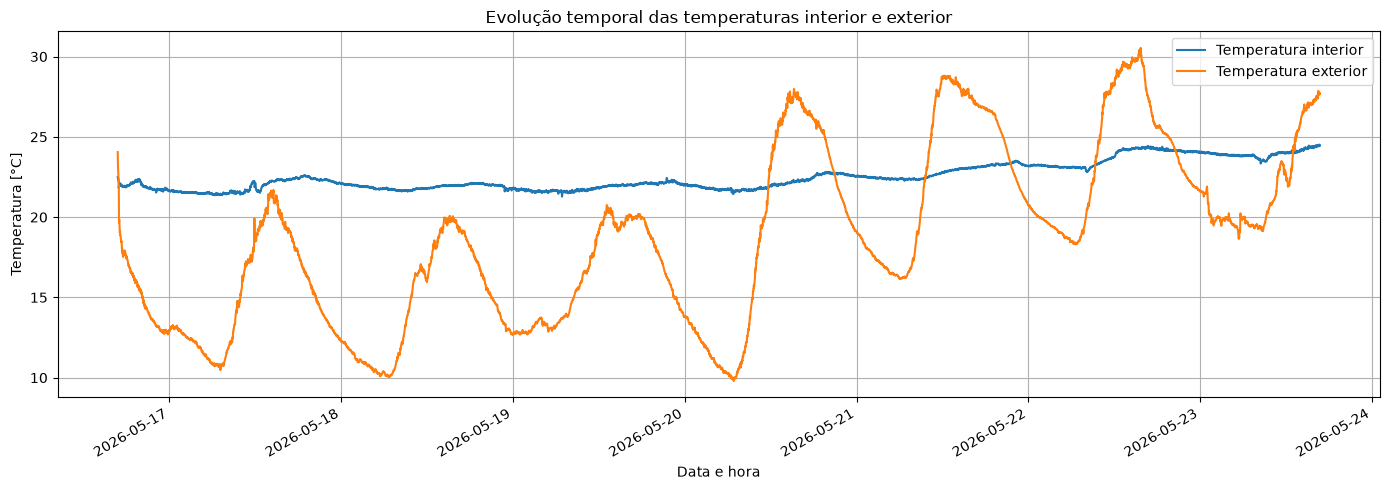

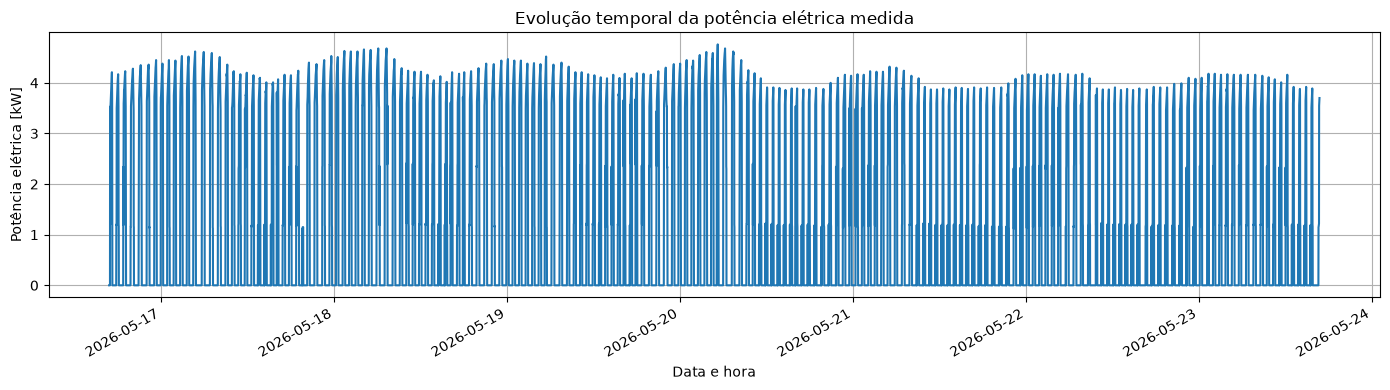

In [31]:
# ============================================================
# Célula 26 — Visualização Temporal dos Dados Experimentais
# ============================================================

import matplotlib.pyplot as plt

print("=" * 60)
print("VISUALIZAÇÃO TEMPORAL DOS DADOS EXPERIMENTAIS")
print("=" * 60)

# ------------------------------------------------------------
# Temperaturas
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    dados_sincronizados["DataHora"],
    dados_sincronizados["T_int"],
    label="Temperatura interior",
)

ax.plot(
    dados_sincronizados["DataHora"],
    dados_sincronizados["T_ext"],
    label="Temperatura exterior",
)

ax.set_xlabel("Data e hora")
ax.set_ylabel("Temperatura [°C]")
ax.set_title(
    "Evolução temporal das temperaturas interior e exterior"
)

ax.legend()
ax.grid(True)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Potência elétrica
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 4)
)

ax.plot(
    dados_sincronizados["DataHora"],
    dados_sincronizados["PSum"],
)

ax.set_xlabel("Data e hora")
ax.set_ylabel("Potência elétrica [kW]")
ax.set_title(
    "Evolução temporal da potência elétrica medida"
)

ax.grid(True)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# Célula 27 — Caracterização Diária dos Dados Experimentais
# ============================================================

print("=" * 60)
print("CARACTERIZAÇÃO DIÁRIA DOS DADOS EXPERIMENTAIS")
print("=" * 60)

# ------------------------------------------------------------
# DataFrame auxiliar
# ------------------------------------------------------------

dados_diarios = (
    dados_sincronizados[
        [
            "DataHora",
            "PSum",
            "T_int",
            "T_ext",
        ]
    ]
    .copy()
)

dados_diarios["Data"] = (
    dados_diarios["DataHora"].dt.date
)

dados_diarios["Sistema_Ativo"] = (
    dados_diarios["PSum"] > 0
)

# ------------------------------------------------------------
# Identificação dos ciclos ativos no conjunto completo
# ------------------------------------------------------------

dados_diarios["Inicio_Ciclo"] = (
    dados_diarios["Sistema_Ativo"]
    & ~dados_diarios["Sistema_Ativo"].shift(
        fill_value=False
    )
)

# ------------------------------------------------------------
# Caracterização por dia
# ------------------------------------------------------------

caracterizacao_diaria = (
    dados_diarios
    .groupby(
        "Data",
        as_index=False,
    )
    .agg(
        Numero_Registos=("DataHora", "size"),
        PSum_Media_kW=("PSum", "mean"),
        PSum_Maxima_kW=("PSum", "max"),
        T_int_Media_C=("T_int", "mean"),
        T_int_Minima_C=("T_int", "min"),
        T_int_Maxima_C=("T_int", "max"),
        T_ext_Media_C=("T_ext", "mean"),
        T_ext_Minima_C=("T_ext", "min"),
        T_ext_Maxima_C=("T_ext", "max"),
        Registos_Ativos=("Sistema_Ativo", "sum"),
        Numero_Ciclos=("Inicio_Ciclo", "sum"),
    )
)

# ------------------------------------------------------------
# Cálculo das amplitudes térmicas
# ------------------------------------------------------------

caracterizacao_diaria["Amplitude_T_int_C"] = (
    caracterizacao_diaria["T_int_Maxima_C"]
    - caracterizacao_diaria["T_int_Minima_C"]
)

caracterizacao_diaria["Amplitude_T_ext_C"] = (
    caracterizacao_diaria["T_ext_Maxima_C"]
    - caracterizacao_diaria["T_ext_Minima_C"]
)

# ------------------------------------------------------------
# Percentagem de funcionamento
# ------------------------------------------------------------

caracterizacao_diaria["Percentagem_Ativo"] = (
    caracterizacao_diaria["Registos_Ativos"]
    / caracterizacao_diaria["Numero_Registos"]
    * 100
)

# ------------------------------------------------------------
# Organização das colunas
# ------------------------------------------------------------

caracterizacao_diaria = (
    caracterizacao_diaria[
        [
            "Data",
            "Numero_Registos",
            "Numero_Ciclos",
            "Percentagem_Ativo",
            "PSum_Media_kW",
            "PSum_Maxima_kW",
            "T_int_Media_C",
            "T_int_Minima_C",
            "T_int_Maxima_C",
            "Amplitude_T_int_C",
            "T_ext_Media_C",
            "T_ext_Minima_C",
            "T_ext_Maxima_C",
            "Amplitude_T_ext_C",
        ]
    ]
)

# ------------------------------------------------------------
# Apresentação dos resultados
# ------------------------------------------------------------

print(
    f"\nNúmero de dias abrangidos: "
    f"{len(caracterizacao_diaria)}"
)

print("\nCaracterização diária:\n")

print(
    caracterizacao_diaria.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.3f}",
    )
)

CARACTERIZAÇÃO DIÁRIA DOS DADOS EXPERIMENTAIS

Número de dias abrangidos: 8

Caracterização diária:

      Data  Numero_Registos  Numero_Ciclos  Percentagem_Ativo  PSum_Media_kW  PSum_Maxima_kW  T_int_Media_C  T_int_Minima_C  T_int_Maxima_C  Amplitude_T_int_C  T_ext_Media_C  T_ext_Minima_C  T_ext_Maxima_C  Amplitude_T_ext_C
2026-05-16              435              8             38.391          1.359           4.450         21.914          21.531          22.490              0.959         15.232          12.690          24.050             11.360
2026-05-17             1440             29             37.153          1.329           4.620         21.906          21.360          22.615              1.255         15.101          10.470          21.695             11.225
2026-05-18             1440             28             37.500          1.350           4.680         21.884          21.594          22.142              0.547         14.622          10.044          20.073             10.028

In [33]:
# ============================================================
# Célula 28 — Divisão dos Dados para Identificação e Validação
# ============================================================

print("=" * 60)
print("DIVISÃO DOS DADOS PARA IDENTIFICAÇÃO E VALIDAÇÃO")
print("=" * 60)

# ------------------------------------------------------------
# Configuração da divisão
# ------------------------------------------------------------

AMOSTRAS_POR_DIA = 1440
DIAS_IDENTIFICACAO = 5

numero_amostras_identificacao = (
    AMOSTRAS_POR_DIA
    * DIAS_IDENTIFICACAO
)

# ------------------------------------------------------------
# Criação dos conjuntos
# ------------------------------------------------------------

dados_identificacao = (
    dados_sincronizados
    .iloc[:numero_amostras_identificacao]
    .copy()
    .reset_index(drop=True)
)

dados_validacao = (
    dados_sincronizados
    .iloc[numero_amostras_identificacao:]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Verificação da continuidade temporal
# ------------------------------------------------------------

intervalo_fronteira_s = (
    dados_validacao["DataHora"].iloc[0]
    - dados_identificacao["DataHora"].iloc[-1]
).total_seconds()

# ------------------------------------------------------------
# Resumo
# ------------------------------------------------------------

print("\nConjunto de identificação:")

print(
    f"  Número de registos : "
    f"{len(dados_identificacao)}"
)

print(
    f"  Primeiro instante  : "
    f"{dados_identificacao['DataHora'].iloc[0]}"
)

print(
    f"  Último instante    : "
    f"{dados_identificacao['DataHora'].iloc[-1]}"
)

print("\nConjunto de validação:")

print(
    f"  Número de registos : "
    f"{len(dados_validacao)}"
)

print(
    f"  Primeiro instante  : "
    f"{dados_validacao['DataHora'].iloc[0]}"
)

print(
    f"  Último instante    : "
    f"{dados_validacao['DataHora'].iloc[-1]}"
)

print(
    f"\nIntervalo na fronteira: "
    f"{intervalo_fronteira_s:.1f} s"
)

# ------------------------------------------------------------
# Verificações finais
# ------------------------------------------------------------

numero_total = (
    len(dados_identificacao)
    + len(dados_validacao)
)

if numero_total != len(dados_sincronizados):
    raise ValueError(
        "A divisão dos dados não preservou "
        "o número total de registos."
    )

if intervalo_fronteira_s != 60.0:
    raise ValueError(
        "Foi detetada uma descontinuidade temporal "
        "entre identificação e validação."
    )

print(
    "\nDivisão dos dados concluída com sucesso."
)

DIVISÃO DOS DADOS PARA IDENTIFICAÇÃO E VALIDAÇÃO

Conjunto de identificação:
  Número de registos : 7200
  Primeiro instante  : 2026-05-16 16:45:55
  Último instante    : 2026-05-21 16:44:55

Conjunto de validação:
  Número de registos : 2880
  Primeiro instante  : 2026-05-21 16:45:55
  Último instante    : 2026-05-23 16:44:55

Intervalo na fronteira: 60.0 s

Divisão dos dados concluída com sucesso.


In [34]:
# ============================================================
# Célula 29 — Validação da Formulação Contínua do Modelo 2R2C
# ============================================================

print("=" * 60)
print("VALIDAÇÃO DA FORMULAÇÃO CONTÍNUA DO MODELO 2R2C")
print("=" * 60)

# ------------------------------------------------------------
# Parâmetros exclusivamente para teste da implementação
#
# Estes valores NÃO correspondem aos parâmetros identificados
# do edifício.
# ------------------------------------------------------------

parametros_teste = Modelo_2R2C.Parametros2R2C(
    R_ext=0.01,
    R_m=0.005,
    C_int=1.0e6,
    C_m=1.0e7,
    K_HVAC=3.0,
)

# ------------------------------------------------------------
# Validação dos parâmetros
# ------------------------------------------------------------

Modelo_2R2C.validar_parametros(
    parametros_teste
)

# ------------------------------------------------------------
# Construção das matrizes contínuas
# ------------------------------------------------------------

matrizes_continuas_teste = (
    Modelo_2R2C.construir_matrizes_continuas(
        parametros_teste
    )
)

# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

Modelo_2R2C.mostrar_matrizes_continuas(
    matrizes_continuas_teste
)

# ------------------------------------------------------------
# Verificações adicionais
# ------------------------------------------------------------

print("\n========== VERIFICAÇÕES ==========")

print(
    f"\nDimensão de A: "
    f"{matrizes_continuas_teste.A.shape}"
)

print(
    f"Dimensão de B: "
    f"{matrizes_continuas_teste.B.shape}"
)

print(
    f"Dimensão de C: "
    f"{matrizes_continuas_teste.C.shape}"
)

print(
    f"Dimensão de D: "
    f"{matrizes_continuas_teste.D.shape}"
)

print(
    "\nFormulação contínua do modelo "
    "2R2C validada com sucesso."
)

VALIDAÇÃO DA FORMULAÇÃO CONTÍNUA DO MODELO 2R2C
========== MODELO 2R2C CONTÍNUO ==========

Matriz A:
[[-3.e-04  2.e-04]
 [ 2.e-05 -2.e-05]]

Matriz B:
[[1.e-04 0.e+00]
 [0.e+00 3.e-07]]

Matriz C:
[[1. 0.]]

Matriz D:
[[0. 0.]]

Dimensões:
A = (2, 2)
B = (2, 2)
C = (1, 2)
D = (1, 2)


========== VERIFICAÇÕES ==========

Dimensão de A: (2, 2)
Dimensão de B: (2, 2)
Dimensão de C: (1, 2)
Dimensão de D: (1, 2)

Formulação contínua do modelo 2R2C validada com sucesso.


In [35]:
# ============================================================
# CÉLULA 30
# Validação da discretização do modelo térmico 2R2C
# ============================================================

import importlib

import Codigos.Modelo_2R2C as modelo_2r2c

importlib.reload(modelo_2r2c)

from Codigos.Modelo_2R2C import (
    Parametros2R2C,
    construir_matrizes_continuas,
    discretizar_modelo,
    mostrar_matrizes_discretas,
)


# ============================================================
# Parâmetros exclusivamente destinados ao teste estrutural
# ============================================================

parametros_teste = Parametros2R2C(
    R_ext=0.01,
    R_m=0.005,
    C_int=1.0e6,
    C_m=1.0e7,
    K_HVAC=3.0,
)


# ============================================================
# Construção do modelo contínuo
# ============================================================

matrizes_continuas = construir_matrizes_continuas(
    parametros_teste
)


# ============================================================
# Discretização do modelo
# ============================================================

PERIODO_AMOSTRAGEM_S = 60.0

matrizes_discretas = discretizar_modelo(
    matrizes_continuas,
    periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
)


# ============================================================
# Apresentação dos resultados
# ============================================================

mostrar_matrizes_discretas(
    matrizes_discretas
)


# ============================================================
# Validação final
# ============================================================

assert matrizes_discretas.Ad.shape == (2, 2)
assert matrizes_discretas.Bd.shape == (2, 2)
assert matrizes_discretas.Cd.shape == (1, 2)
assert matrizes_discretas.Dd.shape == (1, 2)

assert (
    matrizes_discretas.periodo_amostragem_s
    == PERIODO_AMOSTRAGEM_S
)

print()
print(
    "Discretização do modelo 2R2C "
    "para Ts = 60 s validada com sucesso."
)

========== MODELO 2R2C DISCRETO ==========

Período de amostragem: 60.00 s

Matriz Ad:
[[0.98216814 0.01188552]
 [0.00118855 0.99880787]]

Matriz Bd:
[[5.94633681e-03 1.07312041e-07]
 [3.57706803e-06 1.79892473e-05]]

Matriz Cd:
[[1. 0.]]

Matriz Dd:
[[0. 0.]]

Dimensões:
Ad = (2, 2)
Bd = (2, 2)
Cd = (1, 2)
Dd = (1, 2)


Discretização do modelo 2R2C para Ts = 60 s validada com sucesso.


========== SIMULAÇÃO DISCRETA 2R2C ==========

Número de entradas: 10
Período de amostragem: 60.00 s

Dimensões:
Entradas = (10, 2)
Estados = (11, 2)
Saídas = (10, 1)

Estado inicial:
[22. 22.]

Estado final:
[21.61553857 21.99763397]

Primeira saída:
[22.]

Última saída:
[21.65096185]



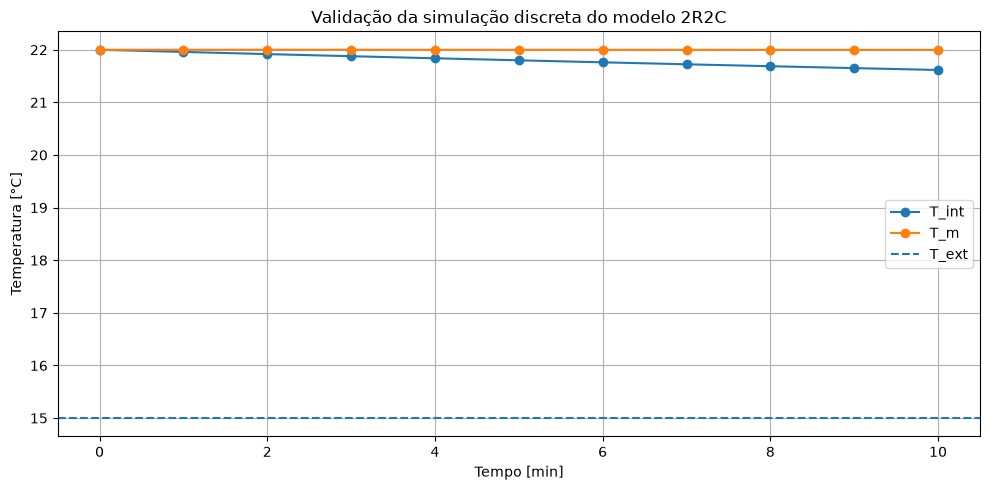


Simulação discreta do modelo 2R2C validada no notebook com sucesso.


In [36]:
# ============================================================
# CÉLULA 31
# Validação da simulação discreta do modelo térmico 2R2C
# ============================================================


from Codigos.Modelo_2R2C import (
    Parametros2R2C,
    construir_matrizes_continuas,
    discretizar_modelo,
    simular_modelo_discreto,
    validar_resultado_simulacao,
    mostrar_resumo_simulacao,
)


# ============================================================
# Parâmetros exclusivamente destinados ao teste estrutural
# ============================================================

parametros_teste = Parametros2R2C(
    R_ext=0.01,
    R_m=0.005,
    C_int=1.0e6,
    C_m=1.0e7,
    K_HVAC=3.0,
)


# ============================================================
# Construção e discretização do modelo
# ============================================================

matrizes_continuas = construir_matrizes_continuas(
    parametros_teste
)

PERIODO_AMOSTRAGEM_S = 60.0

matrizes_discretas = discretizar_modelo(
    matrizes_continuas,
    periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
)


# ============================================================
# Definição do ensaio de simulação
# ============================================================

NUMERO_AMOSTRAS = 10

entradas_teste = np.column_stack(
    (
        np.full(NUMERO_AMOSTRAS, 15.0),
        np.zeros(NUMERO_AMOSTRAS),
    )
)

estado_inicial = np.array(
    [22.0, 22.0],
    dtype=float,
)


# ============================================================
# Simulação
# ============================================================

resultado_simulacao = simular_modelo_discreto(
    matrizes=matrizes_discretas,
    entradas=entradas_teste,
    estado_inicial=estado_inicial,
)

validar_resultado_simulacao(
    resultado_simulacao
)

mostrar_resumo_simulacao(
    resultado_simulacao
)


# ============================================================
# Validação estrutural e física
# ============================================================

assert resultado_simulacao.entradas.shape == (10, 2)

assert resultado_simulacao.estados.shape == (11, 2)

assert resultado_simulacao.saidas.shape == (10, 1)

assert np.all(
    np.isfinite(resultado_simulacao.estados)
)

assert np.all(
    np.isfinite(resultado_simulacao.saidas)
)

assert (
    resultado_simulacao.estados[-1, 0]
    < estado_inicial[0]
)

assert (
    abs(
        resultado_simulacao.estados[-1, 1]
        - estado_inicial[1]
    )
    <
    abs(
        resultado_simulacao.estados[-1, 0]
        - estado_inicial[0]
    )
)


# ============================================================
# Vetor temporal
# ============================================================

tempo_min = (
    np.arange(NUMERO_AMOSTRAS + 1)
    * PERIODO_AMOSTRAGEM_S
    / 60.0
)


# ============================================================
# Representação gráfica dos estados
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    tempo_min,
    resultado_simulacao.estados[:, 0],
    marker="o",
    label="T_int",
)

plt.plot(
    tempo_min,
    resultado_simulacao.estados[:, 1],
    marker="o",
    label="T_m",
)

plt.axhline(
    y=15.0,
    linestyle="--",
    label="T_ext",
)

plt.xlabel("Tempo [min]")
plt.ylabel("Temperatura [°C]")

plt.title(
    "Validação da simulação discreta do modelo 2R2C"
)

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Resultado final
# ============================================================

print()
print(
    "Simulação discreta do modelo 2R2C "
    "validada no notebook com sucesso."
)

In [37]:
# ============================================================
# CÉLULA 32
# Preparação dos dados experimentais para identificação
# do modelo térmico 2R2C
# ============================================================


# ============================================================
# Verificação das colunas necessárias
# ============================================================

colunas_necessarias = [
    "DataHora",
    "T_int",
    "T_ext",
    "PSum",
]

colunas_em_falta = [
    coluna
    for coluna in colunas_necessarias
    if coluna not in dados_identificacao.columns
]

if colunas_em_falta:
    raise ValueError(
        "Existem colunas necessárias em falta nos dados "
        f"de identificação: {colunas_em_falta}"
    )


# ============================================================
# Número de amostras
# ============================================================

numero_amostras_identificacao = len(
    dados_identificacao
)

if numero_amostras_identificacao != 7200:
    raise ValueError(
        "Era esperado um conjunto de identificação com "
        f"7200 amostras, mas foram encontradas "
        f"{numero_amostras_identificacao}."
    )


# ============================================================
# Preparação das variáveis experimentais
# ============================================================

temperatura_interior_medida = (
    dados_identificacao["T_int"]
    .to_numpy(dtype=float)
)

temperatura_exterior = (
    dados_identificacao["T_ext"]
    .to_numpy(dtype=float)
)

potencia_eletrica_kw = (
    dados_identificacao["PSum"]
    .to_numpy(dtype=float)
)


# ============================================================
# Conversão da potência elétrica de kW para W
# ============================================================

potencia_eletrica_w = (
    potencia_eletrica_kw * 1000.0
)


# ============================================================
# Construção da matriz de entradas
#
# u[k] = [T_ext[k], PSum[k]]
#
# A potência é fornecida ao modelo em W.
# ============================================================

entradas_identificacao = np.column_stack(
    (
        temperatura_exterior,
        potencia_eletrica_w,
    )
)


# ============================================================
# Saída experimental
#
# y[k] = T_int[k]
# ============================================================

saida_identificacao = (
    temperatura_interior_medida.copy()
)


# ============================================================
# Estado inicial
#
# T_int(0) é conhecido experimentalmente.
# T_m(0) é inicialmente aproximado por T_int(0).
# ============================================================

temperatura_inicial = float(
    temperatura_interior_medida[0]
)

estado_inicial_identificacao = np.array(
    [
        temperatura_inicial,
        temperatura_inicial,
    ],
    dtype=float,
)


# ============================================================
# Validações estruturais
# ============================================================

assert entradas_identificacao.shape == (
    numero_amostras_identificacao,
    2,
)

assert saida_identificacao.shape == (
    numero_amostras_identificacao,
)

assert estado_inicial_identificacao.shape == (2,)

assert np.all(
    np.isfinite(entradas_identificacao)
)

assert np.all(
    np.isfinite(saida_identificacao)
)

assert np.all(
    np.isfinite(estado_inicial_identificacao)
)


# ============================================================
# Validação das grandezas físicas
# ============================================================

if np.any(potencia_eletrica_w < 0):
    raise ValueError(
        "Foram encontrados valores negativos de potência "
        "elétrica no conjunto de identificação."
    )


# ============================================================
# Resumo
# ============================================================

print(
    "========== DADOS PARA IDENTIFICAÇÃO 2R2C ==========\n"
)

print(
    f"Número de amostras: "
    f"{numero_amostras_identificacao}"
)

print(
    f"Entradas: {entradas_identificacao.shape}"
)

print(
    f"Saída medida: {saida_identificacao.shape}"
)

print(
    f"Estado inicial: {estado_inicial_identificacao.shape}"
)

print("\nPrimeiro instante:")

print(
    dados_identificacao["DataHora"].iloc[0]
)

print("\nÚltimo instante:")

print(
    dados_identificacao["DataHora"].iloc[-1]
)

print("\nEstado inicial adotado:")

print(
    f"T_int(0) = "
    f"{estado_inicial_identificacao[0]:.3f} °C"
)

print(
    f"T_m(0)   = "
    f"{estado_inicial_identificacao[1]:.3f} °C"
)

print("\nIntervalos das entradas:")

print(
    f"T_ext: "
    f"{temperatura_exterior.min():.3f} "
    f"a {temperatura_exterior.max():.3f} °C"
)

print(
    f"PSum: "
    f"{potencia_eletrica_w.min():.1f} "
    f"a {potencia_eletrica_w.max():.1f} W"
)

print("\nIntervalo da saída medida:")

print(
    f"T_int: "
    f"{temperatura_interior_medida.min():.3f} "
    f"a {temperatura_interior_medida.max():.3f} °C"
)

print(
    "\nPreparação dos dados para identificação "
    "validada com sucesso."
)

print(
    "\n==================================================="
)

========== DADOS PARA IDENTIFICAÇÃO 2R2C ==========

Número de amostras: 7200
Entradas: (7200, 2)
Saída medida: (7200,)
Estado inicial: (2,)

Primeiro instante:
2026-05-16 16:45:55

Último instante:
2026-05-21 16:44:55

Estado inicial adotado:
T_int(0) = 22.490 °C
T_m(0)   = 22.490 °C

Intervalos das entradas:
T_ext: 9.810 a 28.804 °C
PSum: 0.0 a 4760.0 W

Intervalo da saída medida:
T_int: 21.279 a 23.130 °C

Preparação dos dados para identificação validada com sucesso.



========== VALIDAÇÃO PRÉ-OTIMIZAÇÃO 2R2C ==========

Ponto inicial em escala log10:
[-2.5     -2.5      5.5      7.5      0.30103]

Parâmetros físicos iniciais:
R_ext  = 3.162278e-03 K/W
R_m    = 3.162278e-03 K/W
C_int  = 3.162278e+05 J/K
C_m    = 3.162278e+07 J/K
K_HVAC = 2.000000

Simulação:
Número de amostras: 7200
Temperatura simulada mínima: 17.582 °C
Temperatura simulada máxima: 30.251 °C
Temperatura simulada inicial: 22.490 °C
Temperatura simulada final: 29.592 °C

Métricas antes da otimização:
RMSE = 3.0086 °C
MAE = 2.3686 °C
Erro médio = -0.5627 °C
Erro máximo absoluto = 7.4163 °C
R² = -60.3317

Simulação pré-otimização executada e validada numericamente com sucesso.



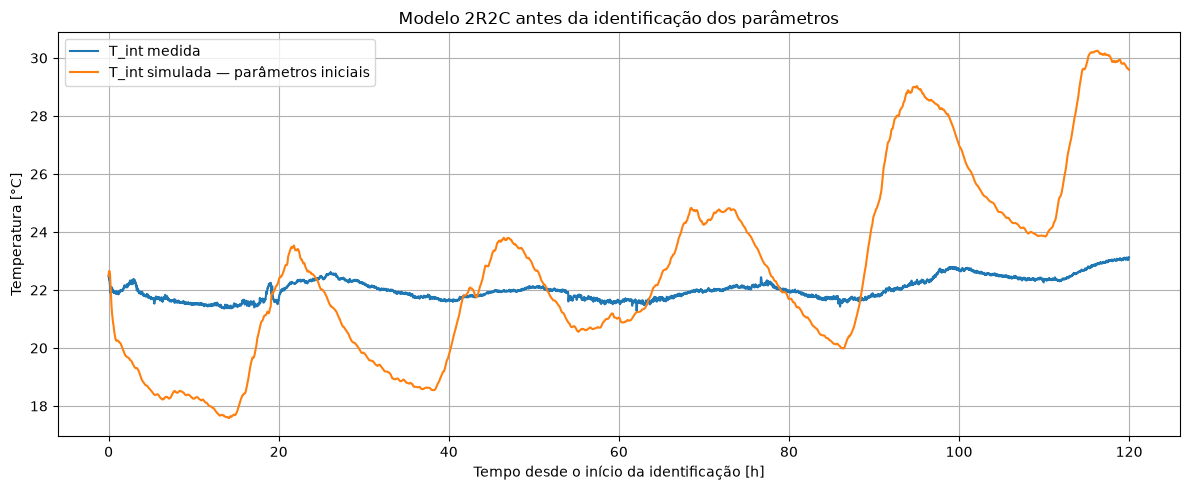

In [41]:
# ============================================================
# CÉLULA 33
# Validação pré-otimização do modelo térmico 2R2C
# com os dados reais de identificação
# ============================================================


# ============================================================
# Definição dos limites da identificação
# ============================================================

limites_identificacao = (
    Identificacao_2R2C.criar_limites_padrao()
)

(
    limites_inferiores_log10,
    limites_superiores_log10,
) = Identificacao_2R2C.obter_limites_log10(
    limites_identificacao
)


# ============================================================
# Definição do ponto inicial
#
# O centro dos limites em escala log10 corresponde à média
# geométrica dos limites físicos.
#
# Estes valores não representam parâmetros identificados.
# São utilizados exclusivamente como ponto inicial de teste.
# ============================================================

vetor_inicial_log10 = (
    limites_inferiores_log10
    + limites_superiores_log10
) / 2.0

parametros_iniciais = (
    Identificacao_2R2C.converter_log10_para_parametros(
        vetor_inicial_log10
    )
)

Identificacao_2R2C.validar_parametros_nos_limites(
    parametros_iniciais,
    limites_identificacao,
)


# ============================================================
# Período de amostragem
# ============================================================

PERIODO_AMOSTRAGEM_S = 60.0


# ============================================================
# Simulação dos dados de identificação
# ============================================================

temperatura_simulada_inicial = (
    Identificacao_2R2C.simular_para_identificacao(
        vetor_log10=vetor_inicial_log10,
        entradas=entradas_identificacao,
        estado_inicial=estado_inicial_identificacao,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ============================================================
# Cálculo dos resíduos
#
# e[k] = T_int_medida[k] - T_int_simulada[k]
# ============================================================

residuos_iniciais = (
    Identificacao_2R2C.calcular_residuos_identificacao(
        vetor_log10=vetor_inicial_log10,
        entradas=entradas_identificacao,
        saida_medida=saida_identificacao,
        estado_inicial=estado_inicial_identificacao,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ============================================================
# Validação estrutural e numérica
# ============================================================

numero_amostras = len(
    saida_identificacao
)

assert numero_amostras == 7200

assert temperatura_simulada_inicial.shape == (
    numero_amostras,
)

assert residuos_iniciais.shape == (
    numero_amostras,
)

assert np.all(
    np.isfinite(temperatura_simulada_inicial)
)

assert np.all(
    np.isfinite(residuos_iniciais)
)


# ============================================================
# Cálculo das métricas iniciais
# ============================================================

rmse_inicial = np.sqrt(
    np.mean(
        residuos_iniciais ** 2
    )
)

mae_inicial = np.mean(
    np.abs(
        residuos_iniciais
    )
)

erro_medio_inicial = np.mean(
    residuos_iniciais
)

erro_maximo_absoluto_inicial = np.max(
    np.abs(
        residuos_iniciais
    )
)


# ============================================================
# Coeficiente de determinação R²
# ============================================================

soma_quadrados_residuos = np.sum(
    residuos_iniciais ** 2
)

soma_quadrados_total = np.sum(
    (
        saida_identificacao
        - np.mean(saida_identificacao)
    ) ** 2
)

if soma_quadrados_total <= 0:
    raise ValueError(
        "Não é possível calcular R² porque a saída "
        "experimental não apresenta variabilidade."
    )

r2_inicial = (
    1.0
    - soma_quadrados_residuos
    / soma_quadrados_total
)


# ============================================================
# Apresentação dos parâmetros iniciais
# ============================================================

print(
    "========== VALIDAÇÃO PRÉ-OTIMIZAÇÃO 2R2C ==========\n"
)

print(
    "Ponto inicial em escala log10:"
)

print(
    vetor_inicial_log10
)

print(
    "\nParâmetros físicos iniciais:"
)

print(
    f"R_ext  = "
    f"{parametros_iniciais.R_ext:.6e} K/W"
)

print(
    f"R_m    = "
    f"{parametros_iniciais.R_m:.6e} K/W"
)

print(
    f"C_int  = "
    f"{parametros_iniciais.C_int:.6e} J/K"
)

print(
    f"C_m    = "
    f"{parametros_iniciais.C_m:.6e} J/K"
)

print(
    f"K_HVAC = "
    f"{parametros_iniciais.K_HVAC:.6f}"
)


# ============================================================
# Resumo da simulação
# ============================================================

print(
    "\nSimulação:"
)

print(
    f"Número de amostras: "
    f"{numero_amostras}"
)

print(
    "Temperatura simulada mínima: "
    f"{temperatura_simulada_inicial.min():.3f} °C"
)

print(
    "Temperatura simulada máxima: "
    f"{temperatura_simulada_inicial.max():.3f} °C"
)

print(
    "Temperatura simulada inicial: "
    f"{temperatura_simulada_inicial[0]:.3f} °C"
)

print(
    "Temperatura simulada final: "
    f"{temperatura_simulada_inicial[-1]:.3f} °C"
)


# ============================================================
# Apresentação das métricas
# ============================================================

print(
    "\nMétricas antes da otimização:"
)

print(
    f"RMSE = "
    f"{rmse_inicial:.4f} °C"
)

print(
    f"MAE = "
    f"{mae_inicial:.4f} °C"
)

print(
    f"Erro médio = "
    f"{erro_medio_inicial:.4f} °C"
)

print(
    f"Erro máximo absoluto = "
    f"{erro_maximo_absoluto_inicial:.4f} °C"
)

print(
    f"R² = "
    f"{r2_inicial:.4f}"
)

print(
    "\nSimulação pré-otimização executada "
    "e validada numericamente com sucesso."
)

print(
    "\n===================================================="
)


# ============================================================
# Construção do vetor temporal
# ============================================================

tempo_horas = (
    np.arange(numero_amostras)
    * PERIODO_AMOSTRAGEM_S
    / 3600.0
)


# ============================================================
# Representação gráfica
# ============================================================

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    tempo_horas,
    saida_identificacao,
    label="T_int medida",
)

plt.plot(
    tempo_horas,
    temperatura_simulada_inicial,
    label="T_int simulada — parâmetros iniciais",
)

plt.xlabel(
    "Tempo desde o início da identificação [h]"
)

plt.ylabel(
    "Temperatura [°C]"
)

plt.title(
    "Modelo 2R2C antes da identificação dos parâmetros"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.show()

In [42]:
# ============================================================
# CÉLULA 34
# Primeira identificação dos parâmetros do modelo 2R2C
# com os dados experimentais
# ============================================================


# ============================================================
# Execução da otimização
#
# Nesta primeira identificação é utilizada uma única
# inicialização, correspondente ao ponto inicial validado
# anteriormente na Célula 33.
# ============================================================

resultado_otimizacao = (
    Otimizacao_2R2C.otimizar_parametros_2r2c(
        vetor_inicial_log10=vetor_inicial_log10,
        limites=limites_identificacao,
        entradas=entradas_identificacao,
        saida_medida=saida_identificacao,
        estado_inicial=estado_inicial_identificacao,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
        maximo_avaliacoes=500,
    )
)


# ============================================================
# Validação estrutural do resultado
# ============================================================

Otimizacao_2R2C.validar_resultado_otimizacao(
    resultado_otimizacao
)


# ============================================================
# Apresentação dos resultados
# ============================================================

Otimizacao_2R2C.mostrar_resultado_otimizacao(
    resultado_otimizacao
)


# ============================================================
# Verificações mínimas obrigatórias
# ============================================================

assert resultado_otimizacao.sucesso

assert (
    resultado_otimizacao.metricas_otimizadas.rmse
    <
    resultado_otimizacao.metricas_iniciais.rmse
)

assert (
    resultado_otimizacao.melhoria_rmse_percentual
    > 0.0
)

assert np.all(
    np.isfinite(
        resultado_otimizacao.temperatura_otimizada
    )
)

assert np.all(
    np.isfinite(
        resultado_otimizacao.residuos_otimizados
    )
)


# ============================================================
# Verificação da relação entre capacitâncias
#
# Esta relação é fisicamente desejável, mas não foi imposta
# como restrição rígida ao algoritmo.
# ============================================================

relacao_capacitancias_valida = (
    resultado_otimizacao
    .parametros_otimizados
    .C_m
    >
    resultado_otimizacao
    .parametros_otimizados
    .C_int
)


# ============================================================
# Resumo adicional
# ============================================================

print()

print(
    "========== DIAGNÓSTICO FÍSICO ==========\n"
)

print(
    "Relação C_m > C_int: "
    f"{relacao_capacitancias_valida}"
)

if (
    resultado_otimizacao
    .parametros_proximos_limites
):
    print(
        "\nAtenção: existem parâmetros próximos "
        "dos limites da identificação."
    )
else:
    print(
        "\nNenhum parâmetro foi identificado "
        "próximo dos limites definidos."
    )

print(
    "\n========================================="
)

========== OTIMIZAÇÃO DO MODELO 2R2C ==========

Convergência: True
Estado do otimizador: 2
Número de avaliações: 21
Mensagem: `ftol` termination condition is satisfied.

Parâmetros iniciais:
R_ext  = 3.162278e-03 K/W
R_m    = 3.162278e-03 K/W
C_int  = 3.162278e+05 J/K
C_m    = 3.162278e+07 J/K
K_HVAC = 2.000000

Parâmetros otimizados:
R_ext  = 9.472681e-03 K/W
R_m    = 7.695200e-04 K/W
C_int  = 1.000000e+07 J/K
C_m    = 6.411565e+07 J/K
K_HVAC = 0.500000

Métricas iniciais:
RMSE = 3.008635 °C
MAE = 2.368564 °C
Erro médio = -0.562664 °C
R² = -60.331701

Métricas otimizadas:
RMSE = 0.173678 °C
MAE = 0.136217 °C
Erro médio = -0.017766 °C
Erro máximo absoluto = 0.580292 °C
R² = 0.795620

Melhoria do RMSE:
94.23 %

Parâmetros próximos dos limites:
  - C_int
  - K_HVAC


========== DIAGNÓSTICO FÍSICO ==========

Relação C_m > C_int: True

Atenção: existem parâmetros próximos dos limites da identificação.



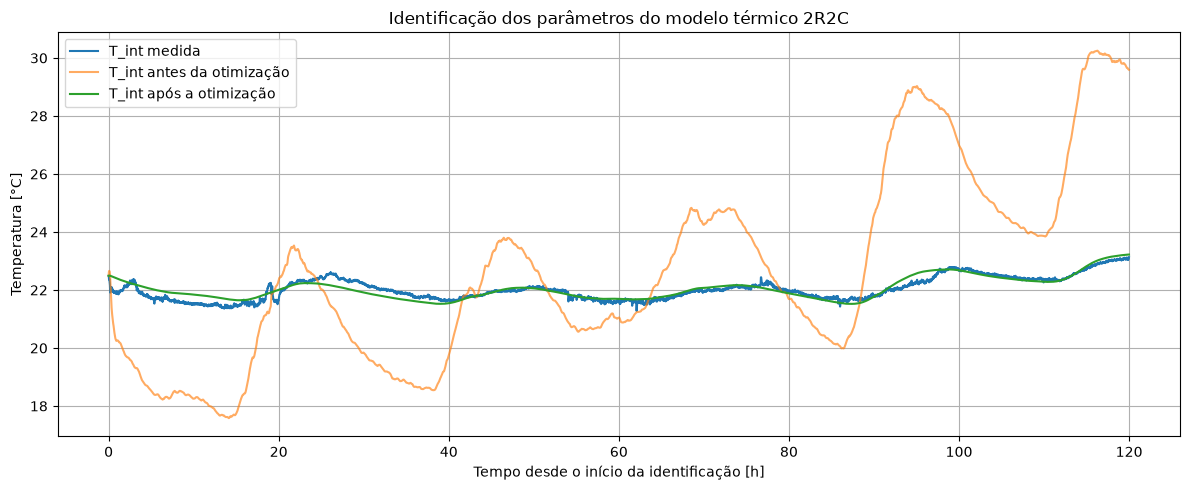

In [43]:
# ============================================================
# CÉLULA 35
# Comparação da temperatura interior medida com o modelo
# antes e depois da identificação dos parâmetros
# ============================================================


# ============================================================
# Extração das temperaturas simuladas
# ============================================================

temperatura_antes_otimizacao = (
    resultado_otimizacao
    .temperatura_inicial
)

temperatura_depois_otimizacao = (
    resultado_otimizacao
    .temperatura_otimizada
)


# ============================================================
# Representação gráfica
# ============================================================

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    tempo_horas,
    saida_identificacao,
    label="T_int medida",
)

plt.plot(
    tempo_horas,
    temperatura_antes_otimizacao,
    label="T_int antes da otimização",
    alpha=0.65,
)

plt.plot(
    tempo_horas,
    temperatura_depois_otimizacao,
    label="T_int após a otimização",
)

plt.xlabel(
    "Tempo desde o início da identificação [h]"
)

plt.ylabel(
    "Temperatura [°C]"
)

plt.title(
    "Identificação dos parâmetros do modelo térmico 2R2C"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.show()

========== ANÁLISE DOS RESÍDUOS 2R2C ==========

Número de resíduos: 7200
Média: -0.017766 °C
Desvio padrão: 0.172767 °C
Resíduo mínimo: -0.580292 °C
Resíduo máximo: 0.456629 °C
Percentil 5 %: -0.319741 °C
Percentil 95 %: 0.262558 °C

Percentagem dos resíduos por intervalo:
|e| <= 0.10 °C : 50.14 %
|e| <= 0.20 °C : 73.64 %
|e| <= 0.50 °C : 99.64 %



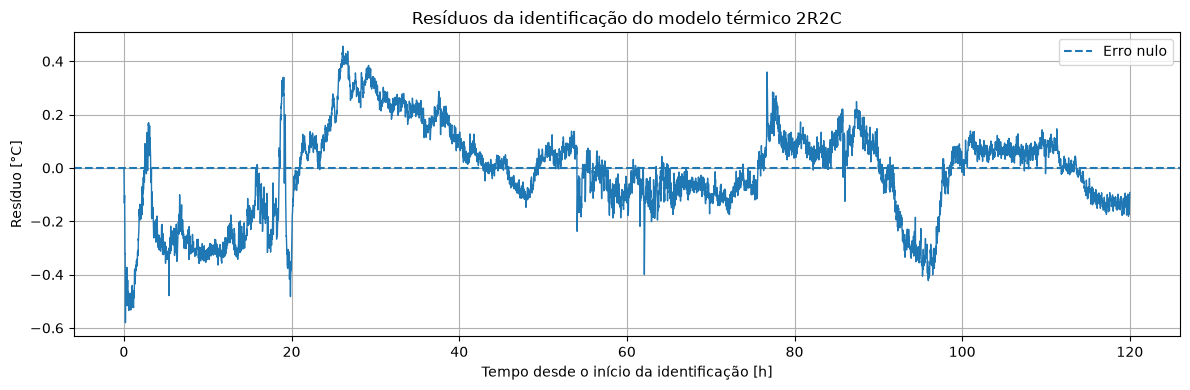

In [44]:
# ============================================================
# CÉLULA 36
# Análise dos resíduos da identificação do modelo térmico 2R2C
# ============================================================


# ============================================================
# Extração dos resíduos otimizados
# ============================================================

residuos_otimizados = (
    resultado_otimizacao
    .residuos_otimizados
)


# ============================================================
# Validação estrutural
# ============================================================

assert residuos_otimizados.shape == (
    len(saida_identificacao),
)

assert np.all(
    np.isfinite(
        residuos_otimizados
    )
)


# ============================================================
# Estatísticas dos resíduos
# ============================================================

media_residuos = np.mean(
    residuos_otimizados
)

desvio_padrao_residuos = np.std(
    residuos_otimizados
)

residuo_minimo = np.min(
    residuos_otimizados
)

residuo_maximo = np.max(
    residuos_otimizados
)

percentil_5 = np.percentile(
    residuos_otimizados,
    5,
)

percentil_95 = np.percentile(
    residuos_otimizados,
    95,
)


# ============================================================
# Percentagem dos resíduos dentro de intervalos
# ============================================================

percentagem_010 = (
    np.mean(
        np.abs(residuos_otimizados)
        <= 0.10
    )
    * 100.0
)

percentagem_020 = (
    np.mean(
        np.abs(residuos_otimizados)
        <= 0.20
    )
    * 100.0
)

percentagem_050 = (
    np.mean(
        np.abs(residuos_otimizados)
        <= 0.50
    )
    * 100.0
)


# ============================================================
# Apresentação das estatísticas
# ============================================================

print(
    "========== ANÁLISE DOS RESÍDUOS 2R2C ==========\n"
)

print(
    f"Número de resíduos: "
    f"{len(residuos_otimizados)}"
)

print(
    f"Média: "
    f"{media_residuos:.6f} °C"
)

print(
    f"Desvio padrão: "
    f"{desvio_padrao_residuos:.6f} °C"
)

print(
    f"Resíduo mínimo: "
    f"{residuo_minimo:.6f} °C"
)

print(
    f"Resíduo máximo: "
    f"{residuo_maximo:.6f} °C"
)

print(
    f"Percentil 5 %: "
    f"{percentil_5:.6f} °C"
)

print(
    f"Percentil 95 %: "
    f"{percentil_95:.6f} °C"
)

print(
    "\nPercentagem dos resíduos por intervalo:"
)

print(
    f"|e| <= 0.10 °C : "
    f"{percentagem_010:.2f} %"
)

print(
    f"|e| <= 0.20 °C : "
    f"{percentagem_020:.2f} %"
)

print(
    f"|e| <= 0.50 °C : "
    f"{percentagem_050:.2f} %"
)

print(
    "\n==============================================="
)


# ============================================================
# Representação temporal dos resíduos
# ============================================================

plt.figure(
    figsize=(12, 4)
)

plt.plot(
    tempo_horas,
    residuos_otimizados,
    linewidth=1.0,
)

plt.axhline(
    y=0.0,
    linestyle="--",
    label="Erro nulo",
)

plt.xlabel(
    "Tempo desde o início da identificação [h]"
)

plt.ylabel(
    "Resíduo [°C]"
)

plt.title(
    "Resíduos da identificação do modelo térmico 2R2C"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.show()

========== AUTOCORRELAÇÃO DOS RESÍDUOS 2R2C ==========

Atraso =   1 min : rho = 0.990202
Atraso =   5 min : rho = 0.968435
Atraso =  10 min : rho = 0.953284
Atraso =  30 min : rho = 0.878708
Atraso =  60 min : rho = 0.789084
Atraso = 120 min : rho = 0.696716
Atraso = 180 min : rho = 0.653371

Primeiro atraso em que |rho| fica abaixo dos limiares:
|rho| < 0.50 : não ocorre até 180 min
|rho| < 0.20 : não ocorre até 180 min
|rho| < 0.10 : não ocorre até 180 min



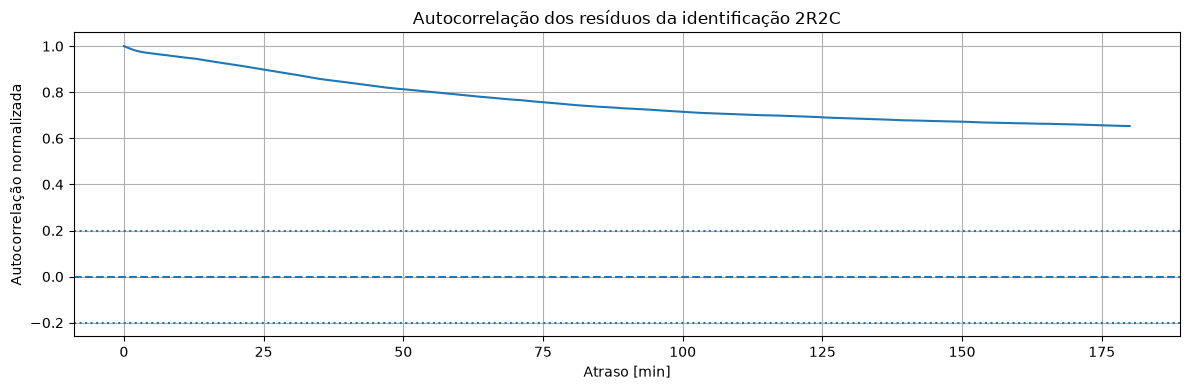

In [45]:
# ============================================================
# CÉLULA 37
# Análise da autocorrelação dos resíduos do modelo térmico 2R2C
# ============================================================


# ============================================================
# Configuração da análise
# ============================================================

ATRASO_MAXIMO_MIN = 180

atraso_maximo_amostras = int(
    ATRASO_MAXIMO_MIN
    * 60
    / PERIODO_AMOSTRAGEM_S
)


# ============================================================
# Centralização dos resíduos
# ============================================================

residuos_centrados = (
    residuos_otimizados
    - np.mean(residuos_otimizados)
)


# ============================================================
# Validação
# ============================================================

if np.allclose(
    residuos_centrados,
    0.0,
):
    raise ValueError(
        "Não é possível calcular a autocorrelação porque "
        "os resíduos não apresentam variabilidade."
    )


# ============================================================
# Cálculo da autocorrelação normalizada
# ============================================================

autocorrelacao_completa = np.correlate(
    residuos_centrados,
    residuos_centrados,
    mode="full",
)

autocorrelacao = (
    autocorrelacao_completa[
        len(residuos_centrados) - 1:
        len(residuos_centrados)
        + atraso_maximo_amostras
    ]
)

autocorrelacao = (
    autocorrelacao
    / autocorrelacao[0]
)


# ============================================================
# Vetor de atrasos
# ============================================================

atrasos_min = (
    np.arange(
        atraso_maximo_amostras + 1
    )
    * PERIODO_AMOSTRAGEM_S
    / 60.0
)


# ============================================================
# Valores específicos para diagnóstico
# ============================================================

atrasos_diagnostico_min = [
    1,
    5,
    10,
    30,
    60,
    120,
    180,
]

print(
    "========== AUTOCORRELAÇÃO DOS RESÍDUOS 2R2C ==========\n"
)

for atraso_min in atrasos_diagnostico_min:

    indice = int(
        atraso_min
        * 60
        / PERIODO_AMOSTRAGEM_S
    )

    print(
        f"Atraso = {atraso_min:3d} min : "
        f"rho = {autocorrelacao[indice]:.6f}"
    )


# ============================================================
# Determinação aproximada do primeiro atraso com
# autocorrelação inferior a determinados limiares
# ============================================================

limiares = [
    0.50,
    0.20,
    0.10,
]

print(
    "\nPrimeiro atraso em que |rho| fica abaixo "
    "dos limiares:"
)

for limiar in limiares:

    indices_validos = np.where(
        np.abs(
            autocorrelacao[1:]
        )
        < limiar
    )[0]

    if len(indices_validos) > 0:

        indice_primeiro = (
            indices_validos[0] + 1
        )

        atraso_primeiro_min = (
            indice_primeiro
            * PERIODO_AMOSTRAGEM_S
            / 60.0
        )

        print(
            f"|rho| < {limiar:.2f} : "
            f"{atraso_primeiro_min:.1f} min"
        )

    else:

        print(
            f"|rho| < {limiar:.2f} : "
            f"não ocorre até "
            f"{ATRASO_MAXIMO_MIN} min"
        )


print(
    "\n======================================================="
)


# ============================================================
# Representação gráfica
# ============================================================

plt.figure(
    figsize=(12, 4)
)

plt.plot(
    atrasos_min,
    autocorrelacao,
)

plt.axhline(
    y=0.0,
    linestyle="--",
)

plt.axhline(
    y=0.2,
    linestyle=":",
)

plt.axhline(
    y=-0.2,
    linestyle=":",
)

plt.xlabel(
    "Atraso [min]"
)

plt.ylabel(
    "Autocorrelação normalizada"
)

plt.title(
    "Autocorrelação dos resíduos da identificação 2R2C"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()

In [46]:
# ============================================================
# CÉLULA 38
# Validação independente do modelo térmico 2R2C
# Preparação e simulação dos 2 dias de validação
# ============================================================


# ============================================================
# Parâmetros identificados
#
# Os parâmetros ficam congelados.
# Não é realizada qualquer nova otimização.
# ============================================================

parametros_identificados = (
    resultado_otimizacao
    .parametros_otimizados
)


# ============================================================
# Reconstrução do modelo identificado
# ============================================================

matrizes_continuas_identificadas = (
    Modelo_2R2C.construir_matrizes_continuas(
        parametros_identificados
    )
)

matrizes_discretas_identificadas = (
    Modelo_2R2C.discretizar_modelo(
        matrizes_continuas_identificadas,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ============================================================
# Propagação completa dos 5 dias de identificação
#
# O objetivo é recuperar o estado do modelo exatamente
# na fronteira entre identificação e validação.
# ============================================================

resultado_estados_identificacao = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_identificadas,
        entradas=entradas_identificacao,
        estado_inicial=estado_inicial_identificacao,
    )
)


# ============================================================
# Estado inicial da validação
#
# Para N = 7200 entradas existem N + 1 estados.
#
# O último estado x[7200] corresponde ao instante seguinte
# à última amostra da identificação, ou seja, à fronteira
# temporal com o primeiro instante da validação.
# ============================================================

estado_inicial_validacao = (
    resultado_estados_identificacao
    .estados[-1]
    .copy()
)


# ============================================================
# Preparação dos dados experimentais de validação
# ============================================================

numero_amostras_validacao = len(
    dados_validacao
)

if numero_amostras_validacao != 2880:
    raise ValueError(
        "Era esperado um conjunto de validação com "
        f"2880 amostras, mas foram encontradas "
        f"{numero_amostras_validacao}."
    )


temperatura_interior_validacao = (
    dados_validacao["T_int"]
    .to_numpy(dtype=float)
)

temperatura_exterior_validacao = (
    dados_validacao["T_ext"]
    .to_numpy(dtype=float)
)

potencia_eletrica_validacao_w = (
    dados_validacao["PSum"]
    .to_numpy(dtype=float)
    * 1000.0
)


# ============================================================
# Matriz de entradas da validação
#
# u[k] = [T_ext[k], PSum[k]]
#
# PSum é fornecida ao modelo em W.
# ============================================================

entradas_validacao = np.column_stack(
    (
        temperatura_exterior_validacao,
        potencia_eletrica_validacao_w,
    )
)


# ============================================================
# Saída experimental de validação
# ============================================================

saida_validacao = (
    temperatura_interior_validacao.copy()
)


# ============================================================
# Validações estruturais
# ============================================================

assert entradas_validacao.shape == (
    2880,
    2,
)

assert saida_validacao.shape == (
    2880,
)

assert estado_inicial_validacao.shape == (
    2,
)

assert np.all(
    np.isfinite(
        entradas_validacao
    )
)

assert np.all(
    np.isfinite(
        saida_validacao
    )
)

assert np.all(
    np.isfinite(
        estado_inicial_validacao
    )
)


# ============================================================
# Simulação independente dos 2 dias de validação
#
# Não são utilizados dados de T_int para corrigir os estados
# durante a simulação.
# ============================================================

resultado_simulacao_validacao = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_identificadas,
        entradas=entradas_validacao,
        estado_inicial=estado_inicial_validacao,
    )
)

temperatura_simulada_validacao = (
    resultado_simulacao_validacao
    .saidas[:, 0]
    .copy()
)


# ============================================================
# Resíduos da validação
#
# e[k] = T_int_medida[k] - T_int_simulada[k]
# ============================================================

residuos_validacao = (
    saida_validacao
    - temperatura_simulada_validacao
)


# ============================================================
# Validações numéricas finais
# ============================================================

assert temperatura_simulada_validacao.shape == (
    2880,
)

assert residuos_validacao.shape == (
    2880,
)

assert np.all(
    np.isfinite(
        temperatura_simulada_validacao
    )
)

assert np.all(
    np.isfinite(
        residuos_validacao
    )
)


# ============================================================
# Métricas da validação independente
# ============================================================

metricas_validacao = (
    Otimizacao_2R2C.calcular_metricas_ajuste(
        saida_medida=saida_validacao,
        temperatura_simulada=temperatura_simulada_validacao,
    )
)


# ============================================================
# Apresentação dos resultados
# ============================================================

print(
    "========== VALIDAÇÃO INDEPENDENTE DO MODELO 2R2C ==========\n"
)

print(
    "Período de validação:"
)

print(
    f"Primeiro instante: "
    f"{dados_validacao['DataHora'].iloc[0]}"
)

print(
    f"Último instante: "
    f"{dados_validacao['DataHora'].iloc[-1]}"
)

print(
    f"\nNúmero de amostras: "
    f"{numero_amostras_validacao}"
)


# ============================================================
# Estado na fronteira identificação / validação
# ============================================================

print(
    "\nEstado transferido da identificação:"
)

print(
    f"T_int modelo = "
    f"{estado_inicial_validacao[0]:.6f} °C"
)

print(
    f"T_m modelo   = "
    f"{estado_inicial_validacao[1]:.6f} °C"
)

print(
    "\nTemperatura interior medida no primeiro "
    "instante de validação:"
)

print(
    f"T_int medida = "
    f"{saida_validacao[0]:.6f} °C"
)


# ============================================================
# Intervalos observados
# ============================================================

print(
    "\nTemperatura medida:"
)

print(
    f"Mínima = "
    f"{saida_validacao.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{saida_validacao.max():.3f} °C"
)

print(
    "\nTemperatura simulada:"
)

print(
    f"Mínima = "
    f"{temperatura_simulada_validacao.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_simulada_validacao.max():.3f} °C"
)


# ============================================================
# Métricas
# ============================================================

print(
    "\nMétricas de validação:"
)

print(
    f"RMSE = "
    f"{metricas_validacao.rmse:.6f} °C"
)

print(
    f"MAE = "
    f"{metricas_validacao.mae:.6f} °C"
)

print(
    f"Erro médio = "
    f"{metricas_validacao.erro_medio:.6f} °C"
)

print(
    f"Erro máximo absoluto = "
    f"{metricas_validacao.erro_maximo_absoluto:.6f} °C"
)

print(
    f"R² = "
    f"{metricas_validacao.r2:.6f}"
)

print(
    "\nValidação independente executada "
    "sem reidentificação dos parâmetros."
)

print(
    "\n============================================================"
)

========== VALIDAÇÃO INDEPENDENTE DO MODELO 2R2C ==========

Período de validação:
Primeiro instante: 2026-05-21 16:45:55
Último instante: 2026-05-23 16:44:55

Número de amostras: 2880

Estado transferido da identificação:
T_int modelo = 23.222777 °C
T_m modelo   = 22.958558 °C

Temperatura interior medida no primeiro instante de validação:
T_int medida = 23.124306 °C

Temperatura medida:
Mínima = 22.821 °C
Máxima = 24.518 °C

Temperatura simulada:
Mínima = 22.984 °C
Máxima = 24.172 °C

Métricas de validação:
RMSE = 0.271243 °C
MAE = 0.235638 °C
Erro médio = 0.221401 °C
Erro máximo absoluto = 0.622033 °C
R² = 0.624060

Validação independente executada sem reidentificação dos parâmetros.



In [47]:
# ============================================================
# CÉLULA 39
# Otimização global do modelo térmico 2R2C
# Dados experimentais de identificação
# ============================================================


# ============================================================
# Configuração da otimização global
#
# Nesta primeira execução com os dados experimentais utiliza-se
# uma configuração computacional moderada.
#
# Os limites físicos permanecem exatamente iguais aos
# utilizados na otimização local.
# ============================================================

MAXIMO_ITERACOES_GLOBAL = 30

POPULACAO_RELATIVA_GLOBAL = 6

TOLERANCIA_GLOBAL = 1.0e-5

SEMENTE_ALEATORIA_GLOBAL = 42

POLIMENTO_FINAL_GLOBAL = True


# ============================================================
# Informação inicial
# ============================================================

print(
    "========== OTIMIZAÇÃO GLOBAL 2R2C ==========\n"
)

print(
    f"Número de amostras de identificação: "
    f"{len(saida_identificacao)}"
)

print(
    f"Período de amostragem: "
    f"{PERIODO_AMOSTRAGEM_S:.2f} s"
)

print(
    f"Máximo de iterações: "
    f"{MAXIMO_ITERACOES_GLOBAL}"
)

print(
    f"População relativa: "
    f"{POPULACAO_RELATIVA_GLOBAL}"
)

print(
    f"Tolerância: "
    f"{TOLERANCIA_GLOBAL:.1e}"
)

print(
    f"Semente aleatória: "
    f"{SEMENTE_ALEATORIA_GLOBAL}"
)

print(
    f"Polimento final: "
    f"{POLIMENTO_FINAL_GLOBAL}"
)

print(
    "\nA iniciar otimização global..."
)


# ============================================================
# Execução da otimização global
# ============================================================

resultado_otimizacao_global = (
    Otimizacao_Global_2R2C
    .otimizar_parametros_global_2r2c(
        limites=limites_identificacao,
        entradas=entradas_identificacao,
        saida_medida=saida_identificacao,
        estado_inicial=estado_inicial_identificacao,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
        maximo_iteracoes=MAXIMO_ITERACOES_GLOBAL,
        populacao_relativa=POPULACAO_RELATIVA_GLOBAL,
        tolerancia=TOLERANCIA_GLOBAL,
        semente_aleatoria=SEMENTE_ALEATORIA_GLOBAL,
        polimento_final=POLIMENTO_FINAL_GLOBAL,
    )
)


# ============================================================
# Validação estrutural do resultado
# ============================================================

Otimizacao_Global_2R2C.validar_resultado_otimizacao_global(
    resultado_otimizacao_global
)


# ============================================================
# Apresentação do resultado
# ============================================================

print()

Otimizacao_Global_2R2C.mostrar_resultado_otimizacao_global(
    resultado_otimizacao_global
)


# ============================================================
# Diagnóstico físico complementar
# ============================================================

parametros_globais = (
    resultado_otimizacao_global
    .parametros_otimizados
)

print(
    "\n========== DIAGNÓSTICO FÍSICO ==========\n"
)

print(
    "Relação C_m > C_int: "
    f"{parametros_globais.C_m > parametros_globais.C_int}"
)

print(
    "\nRelação entre as capacitâncias:"
)

print(
    f"C_m / C_int = "
    f"{parametros_globais.C_m / parametros_globais.C_int:.6f}"
)

print(
    "\nParâmetros próximos dos limites:"
)

if (
    resultado_otimizacao_global
    .parametros_proximos_limites
):

    for nome in (
        resultado_otimizacao_global
        .parametros_proximos_limites
    ):

        print(
            f"  - {nome}"
        )

else:

    print(
        "Nenhum."
    )


# ============================================================
# Validação numérica final
# ============================================================

assert (
    resultado_otimizacao_global
    .temperatura_otimizada
    .shape
    ==
    saida_identificacao.shape
)

assert np.all(
    np.isfinite(
        resultado_otimizacao_global
        .temperatura_otimizada
    )
)

assert np.all(
    np.isfinite(
        resultado_otimizacao_global
        .residuos_otimizados
    )
)

print(
    "\nOtimização global dos dados experimentais "
    "executada e validada numericamente."
)

print(
    "\n========================================="
)

========== OTIMIZAÇÃO GLOBAL 2R2C ==========

Número de amostras de identificação: 7200
Período de amostragem: 60.00 s
Máximo de iterações: 30
População relativa: 6
Tolerância: 1.0e-05
Semente aleatória: 42
Polimento final: True

A iniciar otimização global...

========== OTIMIZAÇÃO GLOBAL DO MODELO 2R2C ==========

Convergência: False
Mensagem: Maximum number of iterations has been exceeded.
Número de iterações: 30
Número de avaliações: 1092
Semente aleatória: 42
População relativa: 6

Parâmetros otimizados:
R_ext  = 1.593995e-02 K/W
R_m    = 1.628197e-03 K/W
C_int  = 1.000000e+07 J/K
C_m    = 6.740645e+08 J/K
K_HVAC = 0.500000

Métricas:
RMSE = 0.181886 °C
MAE = 0.148658 °C
Erro médio = -0.011854 °C
Erro máximo absoluto = 0.580114 °C
R² = 0.775846

Função objetivo:
2.381950250227e+02

Parâmetros próximos dos limites:
  - C_int
  - K_HVAC


========== DIAGNÓSTICO FÍSICO ==========

Relação C_m > C_int: True

Relação entre as capacitâncias:
C_m / C_int = 67.406447

Parâmetros próximos 

In [48]:
# ============================================================
# CÉLULA 40
# Validação independente da solução global do modelo 2R2C
# ============================================================


# ============================================================
# Parâmetros identificados pela otimização global
# ============================================================

parametros_identificados_global = (
    resultado_otimizacao_global
    .parametros_otimizados
)


# ============================================================
# Construção do modelo identificado pela otimização global
# ============================================================

matrizes_continuas_global = (
    Modelo_2R2C.construir_matrizes_continuas(
        parametros_identificados_global
    )
)

matrizes_discretas_global = (
    Modelo_2R2C.discretizar_modelo(
        matrizes_continuas_global,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ============================================================
# Propagação dos estados durante os 5 dias de identificação
#
# O objetivo é recuperar o estado do modelo exatamente na
# fronteira entre identificação e validação.
# ============================================================

resultado_estados_identificacao_global = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_global,
        entradas=entradas_identificacao,
        estado_inicial=estado_inicial_identificacao,
    )
)


# ============================================================
# Estado inicial da validação
# ============================================================

estado_inicial_validacao_global = (
    resultado_estados_identificacao_global
    .estados[-1]
    .copy()
)


# ============================================================
# Simulação dos 2 dias de validação
#
# Utilizam-se exatamente as mesmas entradas de validação já
# preparadas anteriormente.
# ============================================================

resultado_simulacao_validacao_global = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_global,
        entradas=entradas_validacao,
        estado_inicial=estado_inicial_validacao_global,
    )
)

temperatura_simulada_validacao_global = (
    resultado_simulacao_validacao_global
    .saidas[:, 0]
    .copy()
)


# ============================================================
# Resíduos da validação global
# ============================================================

residuos_validacao_global = (
    saida_validacao
    - temperatura_simulada_validacao_global
)


# ============================================================
# Validações estruturais
# ============================================================

assert temperatura_simulada_validacao_global.shape == (
    len(saida_validacao),
)

assert residuos_validacao_global.shape == (
    len(saida_validacao),
)

assert np.all(
    np.isfinite(
        temperatura_simulada_validacao_global
    )
)

assert np.all(
    np.isfinite(
        residuos_validacao_global
    )
)


# ============================================================
# Cálculo das métricas
# ============================================================

metricas_validacao_global = (
    Otimizacao_2R2C.calcular_metricas_ajuste(
        saida_medida=saida_validacao,
        temperatura_simulada=temperatura_simulada_validacao_global,
    )
)


# ============================================================
# Apresentação dos resultados
# ============================================================

print(
    "========== VALIDAÇÃO INDEPENDENTE — OTIMIZAÇÃO GLOBAL ==========\n"
)

print(
    "Estado transferido da identificação:"
)

print(
    f"T_int modelo = "
    f"{estado_inicial_validacao_global[0]:.6f} °C"
)

print(
    f"T_m modelo   = "
    f"{estado_inicial_validacao_global[1]:.6f} °C"
)

print(
    "\nTemperatura interior medida no primeiro "
    "instante de validação:"
)

print(
    f"T_int medida = "
    f"{saida_validacao[0]:.6f} °C"
)


# ============================================================
# Intervalos observados
# ============================================================

print(
    "\nTemperatura medida:"
)

print(
    f"Mínima = "
    f"{saida_validacao.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{saida_validacao.max():.3f} °C"
)

print(
    "\nTemperatura simulada:"
)

print(
    f"Mínima = "
    f"{temperatura_simulada_validacao_global.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_simulada_validacao_global.max():.3f} °C"
)


# ============================================================
# Métricas
# ============================================================

print(
    "\nMétricas de validação global:"
)

print(
    f"RMSE = "
    f"{metricas_validacao_global.rmse:.6f} °C"
)

print(
    f"MAE = "
    f"{metricas_validacao_global.mae:.6f} °C"
)

print(
    f"Erro médio = "
    f"{metricas_validacao_global.erro_medio:.6f} °C"
)

print(
    f"Erro máximo absoluto = "
    f"{metricas_validacao_global.erro_maximo_absoluto:.6f} °C"
)

print(
    f"R² = "
    f"{metricas_validacao_global.r2:.6f}"
)

print(
    "\nValidação independente da solução global "
    "executada sem reidentificação."
)

print(
    "\n================================================================="
)

========== VALIDAÇÃO INDEPENDENTE — OTIMIZAÇÃO GLOBAL ==========

Estado transferido da identificação:
T_int modelo = 22.978291 °C
T_m modelo   = 22.678143 °C

Temperatura interior medida no primeiro instante de validação:
T_int medida = 23.124306 °C

Temperatura medida:
Mínima = 22.821 °C
Máxima = 24.518 °C

Temperatura simulada:
Mínima = 22.440 °C
Máxima = 23.170 °C

Métricas de validação global:
RMSE = 1.011942 °C
MAE = 0.935492 °C
Erro médio = 0.935492 °C
Erro máximo absoluto = 1.608232 °C
R² = -4.232532

Validação independente da solução global executada sem reidentificação.



In [49]:
# ============================================================
# CÉLULA 41
# Análise de sensibilidade aos limites dos parâmetros
# C_int e K_HVAC
# ============================================================


# ============================================================
# Definição dos cenários
# ============================================================

cenarios_limites = {
    "A_atuais": {
        "C_int_max": 1.0e7,
        "K_HVAC_min": 0.5,
    },

    "B_Cint_alargado": {
        "C_int_max": 5.0e7,
        "K_HVAC_min": 0.5,
    },

    "C_Khvac_alargado": {
        "C_int_max": 1.0e7,
        "K_HVAC_min": 0.2,
    },

    "D_ambos_alargados": {
        "C_int_max": 5.0e7,
        "K_HVAC_min": 0.2,
    },
}


# ============================================================
# Estrutura para guardar resultados
# ============================================================

resultados_sensibilidade = {}


# ============================================================
# Execução dos cenários
# ============================================================

for nome_cenario, configuracao in cenarios_limites.items():

    print()
    print(
        "============================================================"
    )

    print(
        f"CENÁRIO: {nome_cenario}"
    )

    print(
        "============================================================"
    )


    # --------------------------------------------------------
    # Construção dos limites físicos do cenário
    # --------------------------------------------------------

    limites_cenario = (
        Identificacao_2R2C.LimitesIdentificacao2R2C(
            inferiores=np.array(
                [
                    1.0e-4,                       # R_ext
                    1.0e-4,                       # R_m
                    1.0e4,                        # C_int
                    1.0e6,                        # C_m
                    configuracao["K_HVAC_min"],   # K_HVAC
                ],
                dtype=float,
            ),
            superiores=np.array(
                [
                    1.0e-1,                       # R_ext
                    1.0e-1,                       # R_m
                    configuracao["C_int_max"],    # C_int
                    1.0e9,                        # C_m
                    8.0,                          # K_HVAC
                ],
                dtype=float,
            ),
        )
    )

    Identificacao_2R2C.validar_limites_identificacao(
        limites_cenario
    )


    # --------------------------------------------------------
    # Ponto inicial
    #
    # Centro dos limites em escala log10.
    # --------------------------------------------------------

    (
        limites_inf_log10_cenario,
        limites_sup_log10_cenario,
    ) = Identificacao_2R2C.obter_limites_log10(
        limites_cenario
    )

    vetor_inicial_cenario = (
        limites_inf_log10_cenario
        + limites_sup_log10_cenario
    ) / 2.0


    # --------------------------------------------------------
    # Identificação com os 5 dias
    # --------------------------------------------------------

    resultado_id_cenario = (
        Otimizacao_2R2C.otimizar_parametros_2r2c(
            vetor_inicial_log10=vetor_inicial_cenario,
            limites=limites_cenario,
            entradas=entradas_identificacao,
            saida_medida=saida_identificacao,
            estado_inicial=estado_inicial_identificacao,
            periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
            maximo_avaliacoes=500,
        )
    )


    # --------------------------------------------------------
    # Construção do modelo identificado
    # --------------------------------------------------------

    parametros_cenario = (
        resultado_id_cenario
        .parametros_otimizados
    )

    matrizes_continuas_cenario = (
        Modelo_2R2C.construir_matrizes_continuas(
            parametros_cenario
        )
    )

    matrizes_discretas_cenario = (
        Modelo_2R2C.discretizar_modelo(
            matrizes_continuas_cenario,
            periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
        )
    )


    # --------------------------------------------------------
    # Propagação dos estados durante a identificação
    # --------------------------------------------------------

    resultado_estados_id_cenario = (
        Modelo_2R2C.simular_modelo_discreto(
            matrizes=matrizes_discretas_cenario,
            entradas=entradas_identificacao,
            estado_inicial=estado_inicial_identificacao,
        )
    )

    estado_inicial_val_cenario = (
        resultado_estados_id_cenario
        .estados[-1]
        .copy()
    )


    # --------------------------------------------------------
    # Validação independente
    # --------------------------------------------------------

    resultado_val_cenario = (
        Modelo_2R2C.simular_modelo_discreto(
            matrizes=matrizes_discretas_cenario,
            entradas=entradas_validacao,
            estado_inicial=estado_inicial_val_cenario,
        )
    )

    temperatura_val_cenario = (
        resultado_val_cenario
        .saidas[:, 0]
        .copy()
    )

    metricas_val_cenario = (
        Otimizacao_2R2C.calcular_metricas_ajuste(
            saida_medida=saida_validacao,
            temperatura_simulada=temperatura_val_cenario,
        )
    )


    # --------------------------------------------------------
    # Armazenamento dos resultados
    # --------------------------------------------------------

    resultados_sensibilidade[nome_cenario] = {
        "limites": limites_cenario,
        "resultado_identificacao": resultado_id_cenario,
        "metricas_validacao": metricas_val_cenario,
        "estado_inicial_validacao": estado_inicial_val_cenario,
        "temperatura_validacao": temperatura_val_cenario,
    }


    # --------------------------------------------------------
    # Resumo do cenário
    # --------------------------------------------------------

    print()

    print(
        "Parâmetros identificados:"
    )

    print(
        f"R_ext  = "
        f"{parametros_cenario.R_ext:.6e} K/W"
    )

    print(
        f"R_m    = "
        f"{parametros_cenario.R_m:.6e} K/W"
    )

    print(
        f"C_int  = "
        f"{parametros_cenario.C_int:.6e} J/K"
    )

    print(
        f"C_m    = "
        f"{parametros_cenario.C_m:.6e} J/K"
    )

    print(
        f"K_HVAC = "
        f"{parametros_cenario.K_HVAC:.6f}"
    )

    print()

    print(
        "Identificação:"
    )

    print(
        f"RMSE = "
        f"{resultado_id_cenario.metricas_otimizadas.rmse:.6f} °C"
    )

    print(
        f"R² = "
        f"{resultado_id_cenario.metricas_otimizadas.r2:.6f}"
    )

    print()

    print(
        "Validação:"
    )

    print(
        f"RMSE = "
        f"{metricas_val_cenario.rmse:.6f} °C"
    )

    print(
        f"MAE = "
        f"{metricas_val_cenario.mae:.6f} °C"
    )

    print(
        f"Erro médio = "
        f"{metricas_val_cenario.erro_medio:.6f} °C"
    )

    print(
        f"R² = "
        f"{metricas_val_cenario.r2:.6f}"
    )

    print()

    print(
        "Parâmetros próximos dos limites:"
    )

    if (
        resultado_id_cenario
        .parametros_proximos_limites
    ):

        for nome_parametro in (
            resultado_id_cenario
            .parametros_proximos_limites
        ):

            print(
                f"  - {nome_parametro}"
            )

    else:

        print(
            "Nenhum."
        )


CENÁRIO: A_atuais

Parâmetros identificados:
R_ext  = 9.472681e-03 K/W
R_m    = 7.695200e-04 K/W
C_int  = 1.000000e+07 J/K
C_m    = 6.411565e+07 J/K
K_HVAC = 0.500000

Identificação:
RMSE = 0.173678 °C
R² = 0.795620

Validação:
RMSE = 0.271243 °C
MAE = 0.235638 °C
Erro médio = 0.221401 °C
R² = 0.624060

Parâmetros próximos dos limites:
  - C_int
  - K_HVAC

CENÁRIO: B_Cint_alargado

Parâmetros identificados:
R_ext  = 5.647532e-03 K/W
R_m    = 5.370828e-04 K/W
C_int  = 2.582334e+07 J/K
C_m    = 1.198099e+08 J/K
K_HVAC = 0.855046

Identificação:
RMSE = 0.165187 °C
R² = 0.815116

Validação:
RMSE = 0.365564 °C
MAE = 0.316578 °C
Erro médio = 0.311593 °C
R² = 0.317145

Parâmetros próximos dos limites:
Nenhum.

CENÁRIO: C_Khvac_alargado

Parâmetros identificados:
R_ext  = 1.748519e-02 K/W
R_m    = 1.662850e-03 K/W
C_int  = 8.340671e+06 J/K
C_m    = 3.869731e+07 J/K
K_HVAC = 0.276171

Identificação:
RMSE = 0.165187 °C
R² = 0.815116

Validação:
RMSE = 0.365564 °C
MAE = 0.316578 °C
Erro médio =

In [50]:
# ============================================================
# CÉLULA 42
# Verificação da equivalência dinâmica entre parametrizações
# do modelo térmico 2R2C
# ============================================================


# ============================================================
# Cenários a comparar
# ============================================================

cenarios_comparacao = [
    "B_Cint_alargado",
    "C_Khvac_alargado",
    "D_ambos_alargados",
]


# ============================================================
# Estruturas para armazenamento
# ============================================================

coeficientes_identificaveis = {}

matrizes_continuas_cenarios = {}

matrizes_discretas_cenarios = {}


# ============================================================
# Construção dos coeficientes e matrizes
# ============================================================

for nome_cenario in cenarios_comparacao:

    resultado_cenario = (
        resultados_sensibilidade[
            nome_cenario
        ]["resultado_identificacao"]
    )

    parametros = (
        resultado_cenario
        .parametros_otimizados
    )


    # --------------------------------------------------------
    # Coeficientes efetivamente presentes nas matrizes
    # --------------------------------------------------------

    a1 = (
        1.0
        / (
            parametros.R_ext
            * parametros.C_int
        )
    )

    a2 = (
        1.0
        / (
            parametros.R_m
            * parametros.C_int
        )
    )

    a3 = (
        1.0
        / (
            parametros.R_m
            * parametros.C_m
        )
    )

    b_hvac = (
        parametros.K_HVAC
        / parametros.C_m
    )

    coeficientes_identificaveis[
        nome_cenario
    ] = np.array(
        [
            a1,
            a2,
            a3,
            b_hvac,
        ],
        dtype=float,
    )


    # --------------------------------------------------------
    # Modelo contínuo
    # --------------------------------------------------------

    matrizes_continuas = (
        Modelo_2R2C.construir_matrizes_continuas(
            parametros
        )
    )

    matrizes_continuas_cenarios[
        nome_cenario
    ] = matrizes_continuas


    # --------------------------------------------------------
    # Modelo discreto
    # --------------------------------------------------------

    matrizes_discretas = (
        Modelo_2R2C.discretizar_modelo(
            matrizes_continuas,
            periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
        )
    )

    matrizes_discretas_cenarios[
        nome_cenario
    ] = matrizes_discretas


# ============================================================
# Apresentação dos coeficientes identificáveis
# ============================================================

print(
    "========== COEFICIENTES IDENTIFICÁVEIS 2R2C ==========\n"
)

for nome_cenario in cenarios_comparacao:

    valores = (
        coeficientes_identificaveis[
            nome_cenario
        ]
    )

    print(
        f"{nome_cenario}:"
    )

    print(
        f"  a1 = {valores[0]:.12e} 1/s"
    )

    print(
        f"  a2 = {valores[1]:.12e} 1/s"
    )

    print(
        f"  a3 = {valores[2]:.12e} 1/s"
    )

    print(
        f"  b  = {valores[3]:.12e} K/(W.s)"
    )

    print()


# ============================================================
# Comparação relativamente ao cenário B
# ============================================================

cenario_referencia = (
    "B_Cint_alargado"
)

coeficientes_referencia = (
    coeficientes_identificaveis[
        cenario_referencia
    ]
)

matrizes_continuas_referencia = (
    matrizes_continuas_cenarios[
        cenario_referencia
    ]
)

matrizes_discretas_referencia = (
    matrizes_discretas_cenarios[
        cenario_referencia
    ]
)


print(
    "========== DIFERENÇAS FACE AO CENÁRIO B ==========\n"
)

for nome_cenario in [
    "C_Khvac_alargado",
    "D_ambos_alargados",
]:

    coeficientes = (
        coeficientes_identificaveis[
            nome_cenario
        ]
    )

    matrizes_continuas = (
        matrizes_continuas_cenarios[
            nome_cenario
        ]
    )

    matrizes_discretas = (
        matrizes_discretas_cenarios[
            nome_cenario
        ]
    )


    # --------------------------------------------------------
    # Diferença máxima dos coeficientes
    # --------------------------------------------------------

    diferenca_coeficientes = np.max(
        np.abs(
            coeficientes
            - coeficientes_referencia
        )
    )


    # --------------------------------------------------------
    # Diferenças das matrizes contínuas
    # --------------------------------------------------------

    diferenca_A = np.max(
        np.abs(
            matrizes_continuas.A
            - matrizes_continuas_referencia.A
        )
    )

    diferenca_B = np.max(
        np.abs(
            matrizes_continuas.B
            - matrizes_continuas_referencia.B
        )
    )


    # --------------------------------------------------------
    # Diferenças das matrizes discretas
    # --------------------------------------------------------

    diferenca_Ad = np.max(
        np.abs(
            matrizes_discretas.Ad
            - matrizes_discretas_referencia.Ad
        )
    )

    diferenca_Bd = np.max(
        np.abs(
            matrizes_discretas.Bd
            - matrizes_discretas_referencia.Bd
        )
    )


    print(
        f"{nome_cenario}:"
    )

    print(
        "  Diferença máxima nos coeficientes = "
        f"{diferenca_coeficientes:.12e}"
    )

    print(
        "  Diferença máxima em A  = "
        f"{diferenca_A:.12e}"
    )

    print(
        "  Diferença máxima em B  = "
        f"{diferenca_B:.12e}"
    )

    print(
        "  Diferença máxima em Ad = "
        f"{diferenca_Ad:.12e}"
    )

    print(
        "  Diferença máxima em Bd = "
        f"{diferenca_Bd:.12e}"
    )

    print()


# ============================================================
# Verificação numérica de equivalência
#
# Não exigimos igualdade exata devido às tolerâncias numéricas
# do processo de otimização.
# ============================================================

TOLERANCIA_EQUIVALENCIA = 1.0e-7

for nome_cenario in [
    "C_Khvac_alargado",
    "D_ambos_alargados",
]:

    assert np.allclose(
        coeficientes_identificaveis[
            nome_cenario
        ],
        coeficientes_referencia,
        rtol=1.0e-4,
        atol=TOLERANCIA_EQUIVALENCIA,
    )

    assert np.allclose(
        matrizes_continuas_cenarios[
            nome_cenario
        ].A,
        matrizes_continuas_referencia.A,
        rtol=1.0e-4,
        atol=TOLERANCIA_EQUIVALENCIA,
    )

    assert np.allclose(
        matrizes_continuas_cenarios[
            nome_cenario
        ].B,
        matrizes_continuas_referencia.B,
        rtol=1.0e-4,
        atol=TOLERANCIA_EQUIVALENCIA,
    )

    assert np.allclose(
        matrizes_discretas_cenarios[
            nome_cenario
        ].Ad,
        matrizes_discretas_referencia.Ad,
        rtol=1.0e-4,
        atol=TOLERANCIA_EQUIVALENCIA,
    )

    assert np.allclose(
        matrizes_discretas_cenarios[
            nome_cenario
        ].Bd,
        matrizes_discretas_referencia.Bd,
        rtol=1.0e-4,
        atol=TOLERANCIA_EQUIVALENCIA,
    )


print(
    "Parametrizações B, C e D apresentam "
    "dinâmica numericamente equivalente."
)

========== COEFICIENTES IDENTIFICÁVEIS 2R2C ==========

B_Cint_alargado:
  a1 = 6.856915894975e-06 1/s
  a2 = 7.210183131874e-05 1/s
  a3 = 1.554054480791e-05 1/s
  b  = 7.136693857645e-09 K/(W.s)

C_Khvac_alargado:
  a1 = 6.856913104392e-06 1/s
  a2 = 7.210178596926e-05 1/s
  a3 = 1.554054383266e-05 1/s
  b  = 7.136695333741e-09 K/(W.s)

D_ambos_alargados:
  a1 = 6.856915322609e-06 1/s
  a2 = 7.210183917357e-05 1/s
  a3 = 1.554058122371e-05 1/s
  b  = 7.136708730088e-09 K/(W.s)

========== DIFERENÇAS FACE AO CENÁRIO B ==========

C_Khvac_alargado:
  Diferença máxima nos coeficientes = 4.534948290372e-11
  Diferença máxima em A  = 4.814006616569e-11
  Diferença máxima em B  = 2.790583252656e-12
  Diferença máxima em Ad = 2.873365989586e-09
  Diferença máxima em Bd = 1.664470169766e-10

D_ambos_alargados:
  Diferença máxima nos coeficientes = 3.641579815201e-11
  Diferença máxima em A  = 3.641579815201e-11
  Diferença máxima em B  = 5.723668965136e-13
  Diferença máxima em Ad = 2.177979

In [51]:
# ============================================================
# CÉLULA 43
# Validação da representação por coeficientes com a solução
# real identificada no cenário A
# ============================================================


# ============================================================
# Recuperação da solução física do cenário A
# ============================================================

resultado_cenario_A = (
    resultados_sensibilidade[
        "A_atuais"
    ]["resultado_identificacao"]
)

parametros_cenario_A = (
    resultado_cenario_A
    .parametros_otimizados
)


# ============================================================
# Conversão dos parâmetros físicos para coeficientes
# ============================================================

coeficientes_cenario_A = (
    Modelo_2R2C_Coeficientes
    .converter_parametros_para_coeficientes(
        parametros_cenario_A
    )
)


# ============================================================
# Apresentação dos coeficientes
# ============================================================

Modelo_2R2C_Coeficientes.mostrar_coeficientes(
    coeficientes_cenario_A
)


# ============================================================
# Construção do modelo contínuo pelas duas representações
# ============================================================

matrizes_continuas_fisicas_A = (
    Modelo_2R2C.construir_matrizes_continuas(
        parametros_cenario_A
    )
)

matrizes_continuas_coeficientes_A = (
    Modelo_2R2C_Coeficientes
    .construir_matrizes_continuas_coeficientes(
        coeficientes_cenario_A
    )
)


# ============================================================
# Discretização das duas representações
# ============================================================

matrizes_discretas_fisicas_A = (
    Modelo_2R2C.discretizar_modelo(
        matrizes_continuas_fisicas_A,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)

matrizes_discretas_coeficientes_A = (
    Modelo_2R2C.discretizar_modelo(
        matrizes_continuas_coeficientes_A,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ============================================================
# Comparação das matrizes contínuas
# ============================================================

diferenca_A_continuo = np.max(
    np.abs(
        matrizes_continuas_fisicas_A.A
        - matrizes_continuas_coeficientes_A.A
    )
)

diferenca_B_continuo = np.max(
    np.abs(
        matrizes_continuas_fisicas_A.B
        - matrizes_continuas_coeficientes_A.B
    )
)


# ============================================================
# Comparação das matrizes discretas
# ============================================================

diferenca_Ad = np.max(
    np.abs(
        matrizes_discretas_fisicas_A.Ad
        - matrizes_discretas_coeficientes_A.Ad
    )
)

diferenca_Bd = np.max(
    np.abs(
        matrizes_discretas_fisicas_A.Bd
        - matrizes_discretas_coeficientes_A.Bd
    )
)


# ============================================================
# Simulação da identificação pela representação física
# ============================================================

resultado_simulacao_fisica_A = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_fisicas_A,
        entradas=entradas_identificacao,
        estado_inicial=estado_inicial_identificacao,
    )
)

temperatura_fisica_A = (
    resultado_simulacao_fisica_A
    .saidas[:, 0]
    .copy()
)


# ============================================================
# Simulação da identificação pela representação por
# coeficientes
# ============================================================

resultado_simulacao_coeficientes_A = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_coeficientes_A,
        entradas=entradas_identificacao,
        estado_inicial=estado_inicial_identificacao,
    )
)

temperatura_coeficientes_A = (
    resultado_simulacao_coeficientes_A
    .saidas[:, 0]
    .copy()
)


# ============================================================
# Comparação das temperaturas simuladas
# ============================================================

diferenca_temperatura = np.max(
    np.abs(
        temperatura_fisica_A
        - temperatura_coeficientes_A
    )
)


# ============================================================
# Métricas da representação por coeficientes
# ============================================================

metricas_coeficientes_A = (
    Otimizacao_2R2C.calcular_metricas_ajuste(
        saida_medida=saida_identificacao,
        temperatura_simulada=temperatura_coeficientes_A,
    )
)


# ============================================================
# Apresentação dos resultados
# ============================================================

print()

print(
    "========== EQUIVALÊNCIA REAL — CENÁRIO A ==========\n"
)

print(
    "Diferenças nas matrizes contínuas:"
)

print(
    f"Máxima em A = "
    f"{diferenca_A_continuo:.12e}"
)

print(
    f"Máxima em B = "
    f"{diferenca_B_continuo:.12e}"
)

print(
    "\nDiferenças nas matrizes discretas:"
)

print(
    f"Máxima em Ad = "
    f"{diferenca_Ad:.12e}"
)

print(
    f"Máxima em Bd = "
    f"{diferenca_Bd:.12e}"
)

print(
    "\nDiferença máxima entre temperaturas simuladas:"
)

print(
    f"{diferenca_temperatura:.12e} °C"
)

print(
    "\nMétricas da representação por coeficientes:"
)

print(
    f"RMSE = "
    f"{metricas_coeficientes_A.rmse:.6f} °C"
)

print(
    f"MAE = "
    f"{metricas_coeficientes_A.mae:.6f} °C"
)

print(
    f"Erro médio = "
    f"{metricas_coeficientes_A.erro_medio:.6f} °C"
)

print(
    f"R² = "
    f"{metricas_coeficientes_A.r2:.6f}"
)


# ============================================================
# Validações finais
# ============================================================

assert np.allclose(
    matrizes_continuas_fisicas_A.A,
    matrizes_continuas_coeficientes_A.A,
    rtol=0.0,
    atol=1.0e-15,
)

assert np.allclose(
    matrizes_continuas_fisicas_A.B,
    matrizes_continuas_coeficientes_A.B,
    rtol=0.0,
    atol=1.0e-15,
)

assert np.allclose(
    matrizes_discretas_fisicas_A.Ad,
    matrizes_discretas_coeficientes_A.Ad,
    rtol=0.0,
    atol=1.0e-15,
)

assert np.allclose(
    matrizes_discretas_fisicas_A.Bd,
    matrizes_discretas_coeficientes_A.Bd,
    rtol=0.0,
    atol=1.0e-15,
)

assert np.allclose(
    temperatura_fisica_A,
    temperatura_coeficientes_A,
    rtol=0.0,
    atol=1.0e-12,
)

print()

print(
    "Representação por coeficientes reproduz exatamente "
    "a solução real do cenário A."
)

print(
    "\n====================================================="
)

========== COEFICIENTES DINÂMICOS 2R2C ==========

a1     = 1.055667338978e-05 1/s
a2     = 1.299511322633e-04 1/s
a3     = 2.026824050306e-05 1/s
b_HVAC = 7.798408582540e-09 K/(W.s)


========== EQUIVALÊNCIA REAL — CENÁRIO A ==========

Diferenças nas matrizes contínuas:
Máxima em A = 0.000000000000e+00
Máxima em B = 0.000000000000e+00

Diferenças nas matrizes discretas:
Máxima em Ad = 0.000000000000e+00
Máxima em Bd = 0.000000000000e+00

Diferença máxima entre temperaturas simuladas:
0.000000000000e+00 °C

Métricas da representação por coeficientes:
RMSE = 0.173678 °C
MAE = 0.136217 °C
Erro médio = -0.017766 °C
R² = 0.795620

Representação por coeficientes reproduz exatamente a solução real do cenário A.



In [52]:
# ============================================================
# CÉLULA 44
# Identificação direta dos quatro coeficientes dinâmicos
# do modelo térmico 2R2C com dados experimentais
# ============================================================


# ============================================================
# Limites dos coeficientes
# ============================================================

limites_coeficientes = (
    Identificacao_Coeficientes_2R2C
    .criar_limites_coeficientes_padrao()
)


# ============================================================
# Conversão dos limites para escala log10
# ============================================================

(
    limites_coeficientes_inferiores_log10,
    limites_coeficientes_superiores_log10,
) = (
    Identificacao_Coeficientes_2R2C
    .obter_limites_coeficientes_log10(
        limites_coeficientes
    )
)


# ============================================================
# Ponto inicial
#
# Utiliza-se o centro dos limites em escala log10.
# Esta escolha é independente da solução anteriormente obtida
# com a parametrização física.
# ============================================================

vetor_inicial_coeficientes_log10 = (
    limites_coeficientes_inferiores_log10
    + limites_coeficientes_superiores_log10
) / 2.0


# ============================================================
# Apresentação do ponto inicial
# ============================================================

coeficientes_iniciais_reais = (
    Identificacao_Coeficientes_2R2C
    .converter_log10_para_coeficientes(
        vetor_inicial_coeficientes_log10
    )
)

print(
    "========== IDENTIFICAÇÃO DIRETA DOS COEFICIENTES 2R2C ==========\n"
)

print(
    f"Número de amostras: "
    f"{len(saida_identificacao)}"
)

print(
    f"Período de amostragem: "
    f"{PERIODO_AMOSTRAGEM_S:.2f} s"
)

print(
    "\nCoeficientes do ponto inicial:"
)

print(
    f"a1     = "
    f"{coeficientes_iniciais_reais.a1:.12e} 1/s"
)

print(
    f"a2     = "
    f"{coeficientes_iniciais_reais.a2:.12e} 1/s"
)

print(
    f"a3     = "
    f"{coeficientes_iniciais_reais.a3:.12e} 1/s"
)

print(
    f"b_HVAC = "
    f"{coeficientes_iniciais_reais.b_HVAC:.12e} K/(W.s)"
)

print(
    "\nA iniciar identificação..."
)


# ============================================================
# Identificação direta
# ============================================================

resultado_identificacao_coeficientes = (
    Identificacao_Coeficientes_2R2C
    .identificar_coeficientes_2r2c(
        vetor_inicial_log10=vetor_inicial_coeficientes_log10,
        limites=limites_coeficientes,
        entradas=entradas_identificacao,
        saida_medida=saida_identificacao,
        estado_inicial=estado_inicial_identificacao,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
        maximo_avaliacoes=500,
    )
)


# ============================================================
# Validação estrutural
# ============================================================

Identificacao_Coeficientes_2R2C \
    .validar_resultado_identificacao_coeficientes(
        resultado_identificacao_coeficientes
    )


# ============================================================
# Apresentação do resultado
# ============================================================

print()

Identificacao_Coeficientes_2R2C \
    .mostrar_resultado_identificacao_coeficientes(
        resultado_identificacao_coeficientes
    )


# ============================================================
# Extração dos coeficientes identificados
# ============================================================

coeficientes_identificados_diretos = (
    resultado_identificacao_coeficientes
    .coeficientes_otimizados
)


# ============================================================
# Comparação com os coeficientes do cenário A
# ============================================================

vetor_coeficientes_diretos = np.array(
    [
        coeficientes_identificados_diretos.a1,
        coeficientes_identificados_diretos.a2,
        coeficientes_identificados_diretos.a3,
        coeficientes_identificados_diretos.b_HVAC,
    ],
    dtype=float,
)

vetor_coeficientes_cenario_A = np.array(
    [
        coeficientes_cenario_A.a1,
        coeficientes_cenario_A.a2,
        coeficientes_cenario_A.a3,
        coeficientes_cenario_A.b_HVAC,
    ],
    dtype=float,
)


# ============================================================
# Diferença relativa entre as duas parametrizações
# ============================================================

diferenca_relativa_coeficientes_percentual = (
    (
        vetor_coeficientes_diretos
        - vetor_coeficientes_cenario_A
    )
    / vetor_coeficientes_cenario_A
    * 100.0
)


print(
    "\n========== COMPARAÇÃO COM O CENÁRIO A ==========\n"
)

for indice, nome in enumerate(
    [
        "a1",
        "a2",
        "a3",
        "b_HVAC",
    ]
):

    print(
        f"{nome}: "
        f"{diferenca_relativa_coeficientes_percentual[indice]:+.4f} %"
    )


# ============================================================
# Validações finais
# ============================================================

assert resultado_identificacao_coeficientes.sucesso

assert np.all(
    np.isfinite(
        resultado_identificacao_coeficientes
        .temperatura_otimizada
    )
)

assert np.all(
    np.isfinite(
        resultado_identificacao_coeficientes
        .residuos_otimizados
    )
)

assert (
    resultado_identificacao_coeficientes
    .metricas_otimizadas
    .rmse
    <
    resultado_identificacao_coeficientes
    .metricas_iniciais
    .rmse
)

print()

print(
    "Identificação direta dos coeficientes com os "
    "dados experimentais executada com sucesso."
)

print(
    "\n==========================================================="
)

========== IDENTIFICAÇÃO DIRETA DOS COEFICIENTES 2R2C ==========

Número de amostras: 7200
Período de amostragem: 60.00 s

Coeficientes do ponto inicial:
a1     = 1.000000000000e-03 1/s
a2     = 1.000000000000e-03 1/s
a3     = 1.000000000000e-05 1/s
b_HVAC = 6.324555320337e-08 K/(W.s)

A iniciar identificação...

========== IDENTIFICAÇÃO DIRETA DOS COEFICIENTES 2R2C ==========

Convergência: True
Estado do otimizador: 2
Número de avaliações: 19
Mensagem: `ftol` termination condition is satisfied.

Coeficientes iniciais:
a1     = 1.000000000000e-03 1/s
a2     = 1.000000000000e-03 1/s
a3     = 1.000000000000e-05 1/s
b_HVAC = 6.324555320337e-08 K/(W.s)

Coeficientes identificados:
a1     = 6.856945903208e-06 1/s
a2     = 7.210234193448e-05 1/s
a3     = 1.554067926920e-05 1/s
b_HVAC = 7.136732230622e-09 K/(W.s)

Métricas iniciais:
RMSE = 3.008635 °C
MAE = 2.368564 °C
R² = -60.331701

Métricas após identificação:
RMSE = 0.165187 °C
MAE = 0.123780 °C
Erro médio = -0.014496 °C
Erro máximo abs

In [53]:
# ============================================================
# CÉLULA 45
# Validação independente da identificação direta dos
# coeficientes do modelo térmico 2R2C
# ============================================================


# ============================================================
# Coeficientes identificados diretamente
# ============================================================

coeficientes_identificados_validacao = (
    resultado_identificacao_coeficientes
    .coeficientes_otimizados
)


# ============================================================
# Construção do modelo contínuo
# ============================================================

matrizes_continuas_coeficientes_identificados = (
    Modelo_2R2C_Coeficientes
    .construir_matrizes_continuas_coeficientes(
        coeficientes_identificados_validacao
    )
)


# ============================================================
# Discretização do modelo
# ============================================================

matrizes_discretas_coeficientes_identificados = (
    Modelo_2R2C.discretizar_modelo(
        matrizes_continuas_coeficientes_identificados,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ============================================================
# Propagação dos estados durante os 5 dias de identificação
#
# O objetivo é obter o estado do modelo exatamente na
# fronteira entre identificação e validação.
# ============================================================

resultado_estados_identificacao_coeficientes = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_coeficientes_identificados,
        entradas=entradas_identificacao,
        estado_inicial=estado_inicial_identificacao,
    )
)


# ============================================================
# Estado inicial da validação
# ============================================================

estado_inicial_validacao_coeficientes = (
    resultado_estados_identificacao_coeficientes
    .estados[-1]
    .copy()
)


# ============================================================
# Simulação dos 2 dias de validação
# ============================================================

resultado_simulacao_validacao_coeficientes = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_coeficientes_identificados,
        entradas=entradas_validacao,
        estado_inicial=estado_inicial_validacao_coeficientes,
    )
)

temperatura_simulada_validacao_coeficientes = (
    resultado_simulacao_validacao_coeficientes
    .saidas[:, 0]
    .copy()
)


# ============================================================
# Resíduos da validação
# ============================================================

residuos_validacao_coeficientes = (
    saida_validacao
    - temperatura_simulada_validacao_coeficientes
)


# ============================================================
# Validações estruturais
# ============================================================

assert temperatura_simulada_validacao_coeficientes.shape == (
    len(saida_validacao),
)

assert residuos_validacao_coeficientes.shape == (
    len(saida_validacao),
)

assert np.all(
    np.isfinite(
        temperatura_simulada_validacao_coeficientes
    )
)

assert np.all(
    np.isfinite(
        residuos_validacao_coeficientes
    )
)


# ============================================================
# Cálculo das métricas de validação
# ============================================================

metricas_validacao_coeficientes = (
    Identificacao_Coeficientes_2R2C
    .calcular_metricas_coeficientes(
        saida_medida=saida_validacao,
        temperatura_simulada=temperatura_simulada_validacao_coeficientes,
    )
)


# ============================================================
# Apresentação dos resultados
# ============================================================

print(
    "========== VALIDAÇÃO INDEPENDENTE — COEFICIENTES 2R2C ==========\n"
)

print(
    "Estado transferido da identificação:"
)

print(
    f"T_int modelo = "
    f"{estado_inicial_validacao_coeficientes[0]:.6f} °C"
)

print(
    f"T_m modelo   = "
    f"{estado_inicial_validacao_coeficientes[1]:.6f} °C"
)

print(
    "\nTemperatura interior medida no primeiro "
    "instante de validação:"
)

print(
    f"T_int medida = "
    f"{saida_validacao[0]:.6f} °C"
)


# ============================================================
# Intervalos observados
# ============================================================

print(
    "\nTemperatura medida:"
)

print(
    f"Mínima = "
    f"{saida_validacao.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{saida_validacao.max():.3f} °C"
)

print(
    "\nTemperatura simulada:"
)

print(
    f"Mínima = "
    f"{temperatura_simulada_validacao_coeficientes.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_simulada_validacao_coeficientes.max():.3f} °C"
)


# ============================================================
# Métricas
# ============================================================

print(
    "\nMétricas de validação:"
)

print(
    f"RMSE = "
    f"{metricas_validacao_coeficientes.rmse:.6f} °C"
)

print(
    f"MAE = "
    f"{metricas_validacao_coeficientes.mae:.6f} °C"
)

print(
    f"Erro médio = "
    f"{metricas_validacao_coeficientes.erro_medio:.6f} °C"
)

print(
    f"Erro máximo absoluto = "
    f"{metricas_validacao_coeficientes.erro_maximo_absoluto:.6f} °C"
)

print(
    f"R² = "
    f"{metricas_validacao_coeficientes.r2:.6f}"
)


# ============================================================
# Comparação com o cenário A
# ============================================================

print(
    "\n========== COMPARAÇÃO COM O CENÁRIO A ==========\n"
)

print(
    f"RMSE cenário A = "
    f"{metricas_validacao.rmse:.6f} °C"
)

print(
    f"RMSE coeficientes = "
    f"{metricas_validacao_coeficientes.rmse:.6f} °C"
)

diferenca_rmse_validacao = (
    metricas_validacao_coeficientes.rmse
    - metricas_validacao.rmse
)

print(
    f"Diferença de RMSE = "
    f"{diferenca_rmse_validacao:+.6f} °C"
)

print(
    f"\nR² cenário A = "
    f"{metricas_validacao.r2:.6f}"
)

print(
    f"R² coeficientes = "
    f"{metricas_validacao_coeficientes.r2:.6f}"
)


# ============================================================
# Confirmação final
# ============================================================

print(
    "\nValidação independente da identificação direta "
    "dos coeficientes executada sem reidentificação."
)

print(
    "\n==============================================================="
)

========== VALIDAÇÃO INDEPENDENTE — COEFICIENTES 2R2C ==========

Estado transferido da identificação:
T_int modelo = 23.170249 °C
T_m modelo   = 22.942368 °C

Temperatura interior medida no primeiro instante de validação:
T_int medida = 23.124306 °C

Temperatura medida:
Mínima = 22.821 °C
Máxima = 24.518 °C

Temperatura simulada:
Mínima = 22.933 °C
Máxima = 23.972 °C

Métricas de validação:
RMSE = 0.365561 °C
MAE = 0.316575 °C
Erro médio = 0.311590 °C
Erro máximo absoluto = 0.785689 °C
R² = 0.317156

========== COMPARAÇÃO COM O CENÁRIO A ==========

RMSE cenário A = 0.271243 °C
RMSE coeficientes = 0.365561 °C
Diferença de RMSE = +0.094318 °C

R² cenário A = 0.624060
R² coeficientes = 0.317156

Validação independente da identificação direta dos coeficientes executada sem reidentificação.



In [54]:
# ============================================================
# CÉLULA 46
# Preparação da análise da capacidade preditiva do modelo 2R2C
# ============================================================


# ============================================================
# Horizontes de previsão
# ============================================================

horizontes_previsao_min = np.array(
    [
        30,
        60,
        120,
        240,
    ],
    dtype=int,
)

horizontes_previsao_amostras = (
    horizontes_previsao_min
    * 60
    / PERIODO_AMOSTRAGEM_S
).astype(int)


# ============================================================
# Validação do período de amostragem
# ============================================================

assert np.isclose(
    PERIODO_AMOSTRAGEM_S,
    60.0,
)

assert np.all(
    horizontes_previsao_amostras > 0
)


# ============================================================
# Recuperação do modelo selecionado
# Cenário A
# ============================================================

parametros_modelo_referencia = (
    resultado_cenario_A
    .parametros_otimizados
)

matrizes_continuas_modelo_referencia = (
    Modelo_2R2C.construir_matrizes_continuas(
        parametros_modelo_referencia
    )
)

matrizes_discretas_modelo_referencia = (
    Modelo_2R2C.discretizar_modelo(
        matrizes_continuas_modelo_referencia,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ============================================================
# Obtenção da trajetória de estados durante a validação
# ============================================================

resultado_trajetoria_validacao = (
    Modelo_2R2C.simular_modelo_discreto(
        matrizes=matrizes_discretas_modelo_referencia,
        entradas=entradas_validacao,
        estado_inicial=estado_inicial_validacao,
    )
)

estados_validacao_previsao = (
    resultado_trajetoria_validacao
    .estados
    .copy()
)


# ============================================================
# Validação estrutural
# ============================================================

numero_amostras_validacao = len(
    saida_validacao
)

assert entradas_validacao.shape == (
    numero_amostras_validacao,
    2,
)

assert saida_validacao.shape == (
    numero_amostras_validacao,
)

assert estados_validacao_previsao.shape == (
    numero_amostras_validacao + 1,
    2,
)

assert np.all(
    np.isfinite(
        estados_validacao_previsao
    )
)


# ============================================================
# Apresentação
# ============================================================

print(
    "========== PREPARAÇÃO DA ANÁLISE PREDITIVA 2R2C ==========\n"
)

print(
    f"Número de amostras de validação: "
    f"{numero_amostras_validacao}"
)

print(
    f"Período de amostragem: "
    f"{PERIODO_AMOSTRAGEM_S:.2f} s"
)

print(
    "\nHorizontes de previsão:"
)

for horizonte_min, horizonte_amostras in zip(
    horizontes_previsao_min,
    horizontes_previsao_amostras,
):

    print(
        f"{horizonte_min:>3} min "
        f"= {horizonte_amostras:>3} amostras"
    )

print(
    "\nDimensões:"
)

print(
    f"Entradas de validação = "
    f"{entradas_validacao.shape}"
)

print(
    f"Saída medida = "
    f"{saida_validacao.shape}"
)

print(
    f"Estados disponíveis = "
    f"{estados_validacao_previsao.shape}"
)

print(
    "\nEstado no início da validação:"
)

print(
    f"T_int = "
    f"{estados_validacao_previsao[0, 0]:.6f} °C"
)

print(
    f"T_m   = "
    f"{estados_validacao_previsao[0, 1]:.6f} °C"
)

print(
    "\nPreparação da análise preditiva "
    "validada com sucesso."
)

print(
    "\n=========================================================="
)

========== PREPARAÇÃO DA ANÁLISE PREDITIVA 2R2C ==========

Número de amostras de validação: 2880
Período de amostragem: 60.00 s

Horizontes de previsão:
 30 min =  30 amostras
 60 min =  60 amostras
120 min = 120 amostras
240 min = 240 amostras

Dimensões:
Entradas de validação = (2880, 2)
Saída medida = (2880,)
Estados disponíveis = (2881, 2)

Estado no início da validação:
T_int = 23.222777 °C
T_m   = 22.958558 °C

Preparação da análise preditiva validada com sucesso.



In [55]:
# ============================================================
# CÉLULA 47
# Avaliação da capacidade preditiva do modelo térmico 2R2C
# nos dados experimentais de validação
# ============================================================


# ============================================================
# Execução da análise em múltiplos horizontes
# ============================================================

resultado_analise_preditiva = (
    Previsao_2R2C
    .analisar_horizontes_previsao_2r2c(
        matrizes=matrizes_discretas_modelo_referencia,
        entradas=entradas_validacao,
        saida_medida=saida_validacao,
        estados_modelo=estados_validacao_previsao,
        horizontes_amostras=horizontes_previsao_amostras,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ============================================================
# Validação estrutural
# ============================================================

Previsao_2R2C.validar_resultado_analise_preditiva(
    resultado_analise_preditiva
)


# ============================================================
# Apresentação dos resultados
# ============================================================

Previsao_2R2C.mostrar_resumo_analise_preditiva(
    resultado_analise_preditiva
)


# ============================================================
# Validações finais
# ============================================================

assert (
    len(
        resultado_analise_preditiva
        .resultados
    )
    ==
    len(
        horizontes_previsao_amostras
    )
)

for resultado_horizonte in (
    resultado_analise_preditiva
    .resultados
):

    assert (
        resultado_horizonte
        .numero_previsoes
        > 0
    )

    assert np.all(
        np.isfinite(
            resultado_horizonte
            .temperatura_prevista
        )
    )

    assert np.all(
        np.isfinite(
            resultado_horizonte
            .residuos
        )
    )


print()

print(
    "Análise preditiva do modelo 2R2C "
    "com dados experimentais executada com sucesso."
)


========== CAPACIDADE PREDITIVA DO MODELO 2R2C ==========

Horizonte | Previsões | RMSE [°C] | MAE [°C] | Erro médio [°C] | Erro máx. [°C] | R²
--------------------------------------------------------------------------------------------
      30 min |      2850 |  0.088743 | 0.069926 |        0.052758 |       0.365665 | 0.959387
      60 min |      2820 |  0.134305 | 0.111028 |        0.092797 |       0.429016 | 0.906220
     120 min |      2760 |  0.189121 | 0.162009 |        0.147345 |       0.539959 | 0.811744
     240 min |      2640 |  0.238663 | 0.210751 |        0.200292 |       0.596507 | 0.696752


Análise preditiva do modelo 2R2C com dados experimentais executada com sucesso.


In [56]:
# ============================================================
# CÉLULA 48
# Síntese final das estratégias de identificação e
# seleção do modelo térmico 2R2C de referência
# ============================================================

import pandas as pd


# ============================================================
# Construção da tabela comparativa
# ============================================================

tabela_comparacao_modelos = pd.DataFrame(
    {
        "Estratégia": [
            "Cenário A",
            "Cenário B — C_int alargado",
            "Cenário C — K_HVAC alargado",
            "Cenário D — ambos alargados",
            "Otimização global",
            "Coeficientes diretos",
        ],
        "RMSE identificação [°C]": [
            0.173678,
            0.165187,
            0.165187,
            0.165187,
            0.181886,
            0.165187,
        ],
        "R² identificação": [
            0.795620,
            0.815116,
            0.815116,
            0.815116,
            0.775846,
            0.815116,
        ],
        "RMSE validação [°C]": [
            0.271243,
            0.365564,
            0.365564,
            0.365563,
            1.011942,
            0.365561,
        ],
        "MAE validação [°C]": [
            0.235638,
            0.316578,
            0.316578,
            0.316577,
            0.935492,
            0.316575,
        ],
        "R² validação": [
            0.624060,
            0.317145,
            0.317145,
            0.317149,
            -4.232532,
            0.317156,
        ],
    }
)


# ============================================================
# Generalização
#
# Um valor positivo indica aumento do RMSE quando se passa
# da identificação para a validação independente.
# ============================================================

tabela_comparacao_modelos[
    "Δ RMSE validação-identificação [°C]"
] = (
    tabela_comparacao_modelos[
        "RMSE validação [°C]"
    ]
    -
    tabela_comparacao_modelos[
        "RMSE identificação [°C]"
    ]
)


# ============================================================
# Ordenação apenas para análise
#
# A ordenação não substitui a decisão metodológica.
# ============================================================

tabela_comparacao_modelos_ordenada = (
    tabela_comparacao_modelos
    .sort_values(
        by="RMSE validação [°C]",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# Apresentação
# ============================================================

print(
    "========== COMPARAÇÃO FINAL DOS MODELOS 2R2C ==========\n"
)

display(
    tabela_comparacao_modelos_ordenada
)


# ============================================================
# Identificação da melhor solução em validação
# ============================================================

indice_melhor_validacao = (
    tabela_comparacao_modelos[
        "RMSE validação [°C]"
    ]
    .idxmin()
)

melhor_estrategia_validacao = (
    tabela_comparacao_modelos
    .loc[
        indice_melhor_validacao,
        "Estratégia",
    ]
)

melhor_rmse_validacao = (
    tabela_comparacao_modelos
    .loc[
        indice_melhor_validacao,
        "RMSE validação [°C]",
    ]
)

melhor_r2_validacao = (
    tabela_comparacao_modelos
    .loc[
        indice_melhor_validacao,
        "R² validação",
    ]
)


# ============================================================
# Comparação quantitativa entre cenário A e coeficientes
# diretos
# ============================================================

rmse_validacao_cenario_A = (
    tabela_comparacao_modelos
    .loc[
        tabela_comparacao_modelos[
            "Estratégia"
        ] == "Cenário A",
        "RMSE validação [°C]",
    ]
    .iloc[0]
)

rmse_validacao_coeficientes = (
    tabela_comparacao_modelos
    .loc[
        tabela_comparacao_modelos[
            "Estratégia"
        ] == "Coeficientes diretos",
        "RMSE validação [°C]",
    ]
    .iloc[0]
)

degradacao_coeficientes_percentual = (
    (
        rmse_validacao_coeficientes
        - rmse_validacao_cenario_A
    )
    / rmse_validacao_cenario_A
    * 100.0
)


# ============================================================
# Resultado da seleção
# ============================================================

print(
    "\n========== SELEÇÃO DO MODELO DE REFERÊNCIA ==========\n"
)

print(
    f"Melhor estratégia segundo o RMSE de validação: "
    f"{melhor_estrategia_validacao}"
)

print(
    f"RMSE de validação = "
    f"{melhor_rmse_validacao:.6f} °C"
)

print(
    f"R² de validação = "
    f"{melhor_r2_validacao:.6f}"
)

print(
    "\nComparação com a identificação direta "
    "dos coeficientes:"
)

print(
    f"Aumento relativo do RMSE de validação = "
    f"{degradacao_coeficientes_percentual:.2f} %"
)


# ============================================================
# Modelo formalmente selecionado
# ============================================================

modelo_2r2c_selecionado = "Cenário A"

parametros_2r2c_selecionados = (
    resultado_cenario_A
    .parametros_otimizados
)

coeficientes_2r2c_selecionados = (
    coeficientes_cenario_A
)

matrizes_continuas_2r2c_selecionadas = (
    matrizes_continuas_modelo_referencia
)

matrizes_discretas_2r2c_selecionadas = (
    matrizes_discretas_modelo_referencia
)


# ============================================================
# Validações finais
# ============================================================

assert (
    melhor_estrategia_validacao
    == modelo_2r2c_selecionado
)

assert np.isclose(
    melhor_rmse_validacao,
    0.271243,
    atol=1.0e-6,
)

assert np.isclose(
    melhor_r2_validacao,
    0.624060,
    atol=1.0e-6,
)


# ============================================================
# Conclusão
# ============================================================

print(
    "\nModelo 2R2C selecionado para desenvolvimento do MPC:"
)

print(
    f"  {modelo_2r2c_selecionado}"
)

print(
    "\nA seleção baseia-se prioritariamente no desempenho "
    "obtido no conjunto independente de validação."
)

print(
    "\nO modelo térmico 2R2C de referência foi "
    "formalmente selecionado com sucesso."
)

print(
    "\n======================================================"
)

========== COMPARAÇÃO FINAL DOS MODELOS 2R2C ==========



,Estratégia,RMSE identificação [°C],R² identificação,RMSE validação [°C],MAE validação [°C],R² validação,Δ RMSE validação-identificação [°C]
0,Cenário A,0.173678,0.795620,0.271243,0.235638,0.624060,0.097565
1,Coeficientes diretos,0.165187,0.815116,0.365561,0.316575,0.317156,0.200374
2,Cenário D — ambos alargados,0.165187,0.815116,0.365563,0.316577,0.317149,0.200376
3,Cenário B — C_int alargado,0.165187,0.815116,0.365564,0.316578,0.317145,0.200377
4,Cenário C — K_HVAC alargado,0.165187,0.815116,0.365564,0.316578,0.317145,0.200377
5,Otimização global,0.181886,0.775846,1.011942,0.935492,-4.232532,0.830056



========== SELEÇÃO DO MODELO DE REFERÊNCIA ==========

Melhor estratégia segundo o RMSE de validação: Cenário A
RMSE de validação = 0.271243 °C
R² de validação = 0.624060

Comparação com a identificação direta dos coeficientes:
Aumento relativo do RMSE de validação = 34.77 %

Modelo 2R2C selecionado para desenvolvimento do MPC:
  Cenário A

A seleção baseia-se prioritariamente no desempenho obtido no conjunto independente de validação.

O modelo térmico 2R2C de referência foi formalmente selecionado com sucesso.



In [57]:
# ============================================================
# CÉLULA 49
# Análise experimental da variação minuto a minuto da potência
# ============================================================


# ============================================================
# Recuperação da potência elétrica
#
# PSum encontra-se em kW no DataFrame sincronizado.
# Para o MPC trabalhamos em W.
# ============================================================

potencia_total_w = (
    dados_identificacao["PSum"]
    .to_numpy(dtype=float)
    * 1000.0
)


# ============================================================
# Variação minuto a minuto
# ============================================================

delta_potencia_w = np.diff(
    potencia_total_w
)


# ============================================================
# Validações
# ============================================================

assert potencia_total_w.shape == (
    len(dados_identificacao),
)

assert delta_potencia_w.shape == (
    len(dados_identificacao) - 1,
)

assert np.all(
    np.isfinite(
        potencia_total_w
    )
)

assert np.all(
    np.isfinite(
        delta_potencia_w
    )
)


# ============================================================
# Estatísticas gerais de ΔP
# ============================================================

delta_p_min = np.min(
    delta_potencia_w
)

delta_p_max = np.max(
    delta_potencia_w
)

delta_p_abs_max = np.max(
    np.abs(
        delta_potencia_w
    )
)

delta_p_abs_mediana = np.median(
    np.abs(
        delta_potencia_w
    )
)

delta_p_abs_media = np.mean(
    np.abs(
        delta_potencia_w
    )
)


# ============================================================
# Percentis de |ΔP|
# ============================================================

percentis = [
    50,
    75,
    90,
    95,
    99,
    99.5,
]

valores_percentis = np.percentile(
    np.abs(
        delta_potencia_w
    ),
    percentis,
)


# ============================================================
# Identificação de transições ON/OFF
# ============================================================

estado_ativo = (
    potencia_total_w > 0.0
)

transicao_arranque = (
    (~estado_ativo[:-1])
    &
    estado_ativo[1:]
)

transicao_paragem = (
    estado_ativo[:-1]
    &
    (~estado_ativo[1:])
)

delta_arranque_w = (
    delta_potencia_w[
        transicao_arranque
    ]
)

delta_paragem_w = (
    delta_potencia_w[
        transicao_paragem
    ]
)


# ============================================================
# Estatísticas das transições
# ============================================================

numero_arranques = len(
    delta_arranque_w
)

numero_paragens = len(
    delta_paragem_w
)

delta_arranque_mediano = np.median(
    delta_arranque_w
)

delta_arranque_max = np.max(
    delta_arranque_w
)

delta_paragem_mediano = np.median(
    np.abs(
        delta_paragem_w
    )
)

delta_paragem_max = np.max(
    np.abs(
        delta_paragem_w
    )
)


# ============================================================
# Apresentação dos resultados
# ============================================================

print(
    "========== VARIAÇÃO EXPERIMENTAL DA POTÊNCIA ==========\n"
)

print(
    f"Número de amostras de potência: "
    f"{len(potencia_total_w)}"
)

print(
    f"Número de variações ΔP: "
    f"{len(delta_potencia_w)}"
)

print(
    "\nEstatísticas gerais de ΔP:"
)

print(
    f"ΔP mínimo = "
    f"{delta_p_min:.1f} W"
)

print(
    f"ΔP máximo = "
    f"{delta_p_max:.1f} W"
)

print(
    f"|ΔP| máximo = "
    f"{delta_p_abs_max:.1f} W"
)

print(
    f"|ΔP| médio = "
    f"{delta_p_abs_media:.1f} W"
)

print(
    f"|ΔP| mediano = "
    f"{delta_p_abs_mediana:.1f} W"
)

print(
    "\nPercentis de |ΔP|:"
)

for percentil, valor in zip(
    percentis,
    valores_percentis,
):

    print(
        f"P{percentil:>4} = "
        f"{valor:.1f} W"
    )


print(
    "\nTransições de funcionamento:"
)

print(
    f"Número de arranques = "
    f"{numero_arranques}"
)

print(
    f"Número de paragens = "
    f"{numero_paragens}"
)

print(
    f"ΔP mediano nos arranques = "
    f"{delta_arranque_mediano:.1f} W"
)

print(
    f"ΔP máximo nos arranques = "
    f"{delta_arranque_max:.1f} W"
)

print(
    f"|ΔP| mediano nas paragens = "
    f"{delta_paragem_mediano:.1f} W"
)

print(
    f"|ΔP| máximo nas paragens = "
    f"{delta_paragem_max:.1f} W"
)

print(
    "\n======================================================="
)

========== VARIAÇÃO EXPERIMENTAL DA POTÊNCIA ==========

Número de amostras de potência: 7200
Número de variações ΔP: 7199

Estatísticas gerais de ΔP:
ΔP mínimo = -3590.0 W
ΔP máximo = 3810.0 W
|ΔP| máximo = 3810.0 W
|ΔP| médio = 174.4 W
|ΔP| mediano = 0.0 W

Percentis de |ΔP|:
P  50 = 0.0 W
P  75 = 50.0 W
P  90 = 252.0 W
P  95 = 1200.0 W
P  99 = 2450.2 W
P99.5 = 3490.1 W

Transições de funcionamento:
Número de arranques = 161
Número de paragens = 160
ΔP mediano nos arranques = 1210.0 W
ΔP máximo nos arranques = 3810.0 W
|ΔP| mediano nas paragens = 1180.0 W
|ΔP| máximo nas paragens = 3590.0 W



In [67]:
# ============================================================
# TESTE SINTÉTICO DO CONTROLADOR MPC 2R2C
# ============================================================

import importlib
import numpy as np

import Codigos.MPC_2R2C as mpc_2r2c

importlib.reload(mpc_2r2c)

from Codigos.MPC_2R2C import (
    criar_configuracao_mpc_padrao,
    resolver_mpc_2r2c,
    validar_resultado_mpc,
    mostrar_resultado_mpc,
)


# ============================================================
# Configuração do MPC
# ============================================================

configuracao_mpc = criar_configuracao_mpc_padrao()

print("=" * 60)
print("CONFIGURAÇÃO DO TESTE MPC")
print("=" * 60)

print(
    f"Horizonte de predição (Np): "
    f"{configuracao_mpc.horizonte_predicao}"
)

print(
    f"Horizonte de controlo (Nc): "
    f"{configuracao_mpc.horizonte_controlo}"
)

print(
    "Número de amostras por bloco: "
    f"{configuracao_mpc.horizonte_predicao // configuracao_mpc.horizonte_controlo}"
)

print(
    "Duração de cada bloco: "
    f"{configuracao_mpc.horizonte_predicao // configuracao_mpc.horizonte_controlo} min"
)

print("=" * 60)


# ============================================================
# Condições do teste sintético
# ============================================================

estado_inicial_mpc = np.array(
    [
        19.0,  # T_int [°C]
        19.0,  # T_m [°C]
    ],
    dtype=float,
)

temperatura_exterior_prevista = np.full(
    configuracao_mpc.horizonte_predicao,
    10.0,
    dtype=float,
)

potencia_anterior_w = 0.0

temperatura_referencia = 20.0


# ============================================================
# Resolução do problema MPC
# ============================================================

resultado_mpc = resolver_mpc_2r2c(
    matrizes=matrizes_discretas_2r2c_selecionadas,
    estado_inicial=estado_inicial_mpc,
    temperatura_exterior_prevista=(
        temperatura_exterior_prevista
    ),
    potencia_anterior_w=potencia_anterior_w,
    configuracao=configuracao_mpc,
    temperatura_referencia=temperatura_referencia,
    maximo_iteracoes=300,
)


# ============================================================
# Validação estrutural e numérica
# ============================================================

validar_resultado_mpc(
    resultado=resultado_mpc,
    configuracao=configuracao_mpc,
)


# ============================================================
# Apresentação dos resultados
# ============================================================

mostrar_resultado_mpc(
    resultado=resultado_mpc,
    configuracao=configuracao_mpc,
)


# ============================================================
# Verificações adicionais
# ============================================================

potencia_otima = resultado_mpc.potencia_otima_w
temperatura_prevista = resultado_mpc.temperatura_prevista

print()
print("=" * 60)
print("VALIDAÇÃO ADICIONAL DO TESTE")
print("=" * 60)

print(
    f"Número de valores de potência previstos: "
    f"{potencia_otima.size}"
)

print(
    f"Potência dentro dos limites: "
    f"{bool(np.all(
        (potencia_otima >= configuracao_mpc.potencia_minima_w)
        & (potencia_otima <= configuracao_mpc.potencia_maxima_w)
    ))}"
)

print(
    f"Primeira ação de controlo: "
    f"{resultado_mpc.primeira_acao_w:.2f} W"
)

print(
    f"Temperatura interior inicial: "
    f"{estado_inicial_mpc[0]:.3f} °C"
)

print(
    f"Temperatura prevista final: "
    f"{temperatura_prevista[-1]:.3f} °C"
)

print(
    f"Temperatura prevista mínima: "
    f"{temperatura_prevista.min():.3f} °C"
)

print(
    f"Temperatura prevista máxima: "
    f"{temperatura_prevista.max():.3f} °C"
)

print("=" * 60)

CONFIGURAÇÃO DO TESTE MPC
Horizonte de predição (Np): 120
Horizonte de controlo (Nc): 12
Número de amostras por bloco: 10
Duração de cada bloco: 10 min
========== RESULTADO DO MPC 2R2C ==========

Convergência: True
Estado do otimizador: 0
Mensagem: Optimization terminated successfully
Número de iterações: 5
Número de avaliações: 77

Ação de controlo:
Primeira potência ótima = 4760.00 W
Potência mínima prevista = 3025.54 W
Potência máxima prevista = 4760.00 W

Temperatura prevista:
Inicial prevista = 18.994 °C
Final prevista = 18.648 °C
Mínima prevista = 18.648 °C
Máxima prevista = 18.994 °C

Componentes da função objetivo:
Temperatura = 180.671689
Potência = 5.702005
Variação da potência = 0.113277
Violação de conforto = 6391.744142
Custo total = 6578.231113


VALIDAÇÃO ADICIONAL DO TESTE
Número de valores de potência previstos: 120
Potência dentro dos limites: True
Primeira ação de controlo: 4760.00 W
Temperatura interior inicial: 19.000 °C
Temperatura prevista final: 18.648 °C
Tempe

In [68]:
# ============================================================
# TESTE DE ROBUSTEZ À ESTIMATIVA INICIAL
# ============================================================

import numpy as np

from Codigos.MPC_2R2C import (
    resolver_mpc_2r2c,
)


# ============================================================
# Configurações das três inicializações
# ============================================================

valores_iniciais_w = {
    "0 W": 0.0,
    "2380 W": 2380.0,
    "4760 W": 4760.0,
}

resultados_robustez = {}


# ============================================================
# Execução dos testes
# ============================================================

for nome_teste, valor_inicial_w in valores_iniciais_w.items():

    potencia_inicial_w = np.full(
        configuracao_mpc.horizonte_predicao,
        valor_inicial_w,
        dtype=float,
    )

    resultado = resolver_mpc_2r2c(
        matrizes=matrizes_discretas_2r2c_selecionadas,
        estado_inicial=estado_inicial_mpc,
        temperatura_exterior_prevista=(
            temperatura_exterior_prevista
        ),
        potencia_anterior_w=potencia_anterior_w,
        configuracao=configuracao_mpc,
        temperatura_referencia=temperatura_referencia,
        potencia_inicial_w=potencia_inicial_w,
        maximo_iteracoes=300,
    )

    resultados_robustez[nome_teste] = resultado


# ============================================================
# Apresentação dos resultados
# ============================================================

print("=" * 90)
print("TESTE DE ROBUSTEZ DO MPC À ESTIMATIVA INICIAL")
print("=" * 90)

print(
    f"{'Inicialização':<15}"
    f"{'Sucesso':<10}"
    f"{'Custo':<16}"
    f"{'1.ª ação [W]':<16}"
    f"{'Iterações':<12}"
    f"{'Avaliações':<12}"
)

print("-" * 90)

for nome_teste, resultado in resultados_robustez.items():

    print(
        f"{nome_teste:<15}"
        f"{str(resultado.sucesso):<10}"
        f"{resultado.componentes_custo.custo_total:<16.6f}"
        f"{resultado.primeira_acao_w:<16.2f}"
        f"{resultado.numero_iteracoes:<12}"
        f"{resultado.numero_avaliacoes:<12}"
    )

print("=" * 90)


# ============================================================
# Comparação quantitativa das soluções
# ============================================================

custos = np.array(
    [
        resultado.componentes_custo.custo_total
        for resultado in resultados_robustez.values()
    ],
    dtype=float,
)

primeiras_acoes = np.array(
    [
        resultado.primeira_acao_w
        for resultado in resultados_robustez.values()
    ],
    dtype=float,
)

potencias_otimas = np.vstack(
    [
        resultado.potencia_otima_w
        for resultado in resultados_robustez.values()
    ]
)


diferenca_custos = (
    custos.max()
    - custos.min()
)

diferenca_relativa_custos_percentagem = (
    diferenca_custos
    / custos.min()
    * 100.0
)

diferenca_primeira_acao = (
    primeiras_acoes.max()
    - primeiras_acoes.min()
)

diferenca_maxima_sequencias = (
    np.max(
        np.ptp(
            potencias_otimas,
            axis=0,
        )
    )
)


print()
print("=" * 90)
print("ANÁLISE DE SENSIBILIDADE À INICIALIZAÇÃO")
print("=" * 90)

print(
    f"Custo mínimo = "
    f"{custos.min():.6f}"
)

print(
    f"Custo máximo = "
    f"{custos.max():.6f}"
)

print(
    f"Diferença absoluta entre custos = "
    f"{diferenca_custos:.6f}"
)

print(
    f"Diferença relativa entre custos = "
    f"{diferenca_relativa_custos_percentagem:.6f} %"
)

print(
    f"Diferença máxima na primeira ação = "
    f"{diferenca_primeira_acao:.6f} W"
)

print(
    f"Diferença máxima entre sequências de potência = "
    f"{diferenca_maxima_sequencias:.6f} W"
)

print("=" * 90)


# ============================================================
# Critério preliminar de robustez
# ============================================================

todos_convergiram = all(
    resultado.sucesso
    for resultado in resultados_robustez.values()
)

custos_consistentes = (
    diferenca_relativa_custos_percentagem
    <= 0.01
)

primeiras_acoes_consistentes = (
    diferenca_primeira_acao
    <= 1.0
)


print()
print("=" * 90)
print("VALIDAÇÃO PRELIMINAR DA ROBUSTEZ")
print("=" * 90)

print(
    f"Todas as otimizações convergiram: "
    f"{todos_convergiram}"
)

print(
    f"Custos consistentes "
    f"(diferença ≤ 0.01 %): "
    f"{custos_consistentes}"
)

print(
    f"Primeiras ações consistentes "
    f"(diferença ≤ 1 W): "
    f"{primeiras_acoes_consistentes}"
)

robustez_global = (
    todos_convergiram
    and custos_consistentes
    and primeiras_acoes_consistentes
)

print(
    f"Robustez global da otimização: "
    f"{robustez_global}"
)

print("=" * 90)

TESTE DE ROBUSTEZ DO MPC À ESTIMATIVA INICIAL
Inicialização  Sucesso   Custo           1.ª ação [W]    Iterações   Avaliações  
------------------------------------------------------------------------------------------
0 W            True      6578.231113     4760.00         5           77          
2380 W         True      6578.231113     4760.00         6           90          
4760 W         True      6578.231113     4760.00         6           90          

ANÁLISE DE SENSIBILIDADE À INICIALIZAÇÃO
Custo mínimo = 6578.231113
Custo máximo = 6578.231113
Diferença absoluta entre custos = 0.000000
Diferença relativa entre custos = 0.000000 %
Diferença máxima na primeira ação = 0.000000 W
Diferença máxima entre sequências de potência = 1.302661 W

VALIDAÇÃO PRELIMINAR DA ROBUSTEZ
Todas as otimizações convergiram: True
Custos consistentes (diferença ≤ 0.01 %): True
Primeiras ações consistentes (diferença ≤ 1 W): True
Robustez global da otimização: True


In [66]:
import importlib
import Codigos.MPC_2R2C as mpc_2r2c

importlib.reload(mpc_2r2c)

print("Ficheiro carregado:")
print(mpc_2r2c.__file__)

print("\nFunções disponíveis:")
for nome in dir(mpc_2r2c):
    if not nome.startswith("_"):
        print(nome)

Ficheiro carregado:
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Codigos\MPC_2R2C.py

Funções disponíveis:
ArrayFloat
ArrayLike
ComponentesCustoMPC
ComponentesCustoMPC2R2C
ConfiguracaoMPC2R2C
NDArray
OptimizeResult
ResultadoMPC2R2C
annotations
calcular_componentes_custo_mpc
criar_configuracao_mpc_padrao
dataclass
desnormalizar_potencia_mpc
expandir_acoes_controlo
expandir_potencia_blocos
funcao_objetivo_mpc
minimize
mostrar_resultado_mpc
mostrar_resumo_resultado_mpc
normalizar_potencia_mpc
np
otimizar_mpc_2r2c
perf_counter
preparar_referencia_temperatura
prever_trajetoria_2r2c
prever_trajetoria_mpc
resolver_mpc_2r2c
validar_configuracao_mpc
validar_estado_inicial_mpc
validar_matrizes_discretas_mpc
validar_previsao_temperatura_exterior
validar_resultado_mpc


In [63]:
# ============================================================
# DIAGNÓSTICO DA SOLUÇÃO MPC
# ============================================================

import numpy as np

from Codigos.MPC_2R2C import (
    prever_trajetoria_mpc,
    calcular_componentes_custo_mpc,
    preparar_referencia_temperatura,
)


# ============================================================
# 1. Potência ótima por bloco
# ============================================================

Np = configuracao_mpc.horizonte_predicao
Nc = configuracao_mpc.horizonte_controlo

tamanho_bloco = Np // Nc

potencia_otima = resultado_mpc.potencia_otima_w

potencia_por_bloco = potencia_otima.reshape(
    Nc,
    tamanho_bloco,
)[:, 0]


print("=" * 70)
print("POTÊNCIA ÓTIMA POR BLOCO")
print("=" * 70)

for indice, potencia in enumerate(
    potencia_por_bloco,
    start=1,
):
    minuto_inicial = (
        (indice - 1) * tamanho_bloco
    )

    minuto_final = (
        indice * tamanho_bloco
    )

    print(
        f"Bloco {indice:02d} "
        f"({minuto_inicial:3d}–{minuto_final:3d} min): "
        f"{potencia:8.2f} W"
    )


# ============================================================
# 2. Temperatura prevista no final de cada bloco
# ============================================================

temperatura_prevista = (
    resultado_mpc.temperatura_prevista
)

print()
print("=" * 70)
print("TEMPERATURA NO FINAL DE CADA BLOCO")
print("=" * 70)

for indice in range(Nc):

    posicao = (
        (indice + 1) * tamanho_bloco - 1
    )

    minuto = (
        (indice + 1) * tamanho_bloco
    )

    print(
        f"{minuto:3d} min: "
        f"{temperatura_prevista[posicao]:.4f} °C"
    )


# ============================================================
# 3. Cenário de potência máxima durante as 2 horas
# ============================================================

potencia_maxima = np.full(
    Np,
    configuracao_mpc.potencia_maxima_w,
    dtype=float,
)

(
    estados_pmax,
    temperatura_pmax,
) = prever_trajetoria_mpc(
    matrizes=matrizes_discretas_2r2c_selecionadas,
    estado_inicial=estado_inicial_mpc,
    temperatura_exterior_prevista=(
        temperatura_exterior_prevista
    ),
    potencia_w=potencia_maxima,
)


# ============================================================
# 4. Cenário sem aquecimento
# ============================================================

potencia_zero = np.zeros(
    Np,
    dtype=float,
)

(
    estados_zero,
    temperatura_zero,
) = prever_trajetoria_mpc(
    matrizes=matrizes_discretas_2r2c_selecionadas,
    estado_inicial=estado_inicial_mpc,
    temperatura_exterior_prevista=(
        temperatura_exterior_prevista
    ),
    potencia_w=potencia_zero,
)


# ============================================================
# 5. Comparação das trajetórias
# ============================================================

print()
print("=" * 70)
print("COMPARAÇÃO DAS TRAJETÓRIAS TÉRMICAS")
print("=" * 70)

print(
    f"MPC:"
    f"\n  Final  = {temperatura_prevista[-1]:.4f} °C"
    f"\n  Mínima = {temperatura_prevista.min():.4f} °C"
    f"\n  Máxima = {temperatura_prevista.max():.4f} °C"
)

print()

print(
    f"Potência máxima constante:"
    f"\n  Final  = {temperatura_pmax[-1]:.4f} °C"
    f"\n  Mínima = {temperatura_pmax.min():.4f} °C"
    f"\n  Máxima = {temperatura_pmax.max():.4f} °C"
)

print()

print(
    f"Potência nula:"
    f"\n  Final  = {temperatura_zero[-1]:.4f} °C"
    f"\n  Mínima = {temperatura_zero.min():.4f} °C"
    f"\n  Máxima = {temperatura_zero.max():.4f} °C"
)


# ============================================================
# 6. Comparação da função objetivo
# ============================================================

referencia = preparar_referencia_temperatura(
    temperatura_referencia,
    Np,
)

custo_mpc = resultado_mpc.componentes_custo

custo_pmax = calcular_componentes_custo_mpc(
    matrizes=matrizes_discretas_2r2c_selecionadas,
    estado_inicial=estado_inicial_mpc,
    temperatura_exterior_prevista=(
        temperatura_exterior_prevista
    ),
    potencia_w=potencia_maxima,
    potencia_anterior_w=potencia_anterior_w,
    referencia_temperatura=referencia,
    configuracao=configuracao_mpc,
)

custo_zero = calcular_componentes_custo_mpc(
    matrizes=matrizes_discretas_2r2c_selecionadas,
    estado_inicial=estado_inicial_mpc,
    temperatura_exterior_prevista=(
        temperatura_exterior_prevista
    ),
    potencia_w=potencia_zero,
    potencia_anterior_w=potencia_anterior_w,
    referencia_temperatura=referencia,
    configuracao=configuracao_mpc,
)


print()
print("=" * 70)
print("COMPARAÇÃO DO CUSTO TOTAL")
print("=" * 70)

print(
    f"MPC otimizado       = "
    f"{custo_mpc.custo_total:.6f}"
)

print(
    f"Potência máxima     = "
    f"{custo_pmax.custo_total:.6f}"
)

print(
    f"Potência nula       = "
    f"{custo_zero.custo_total:.6f}"
)

print("=" * 70)

POTÊNCIA ÓTIMA POR BLOCO
Bloco 01 (  0– 10 min):  4759.84 W
Bloco 02 ( 10– 20 min):  4760.00 W
Bloco 03 ( 20– 30 min):  4760.00 W
Bloco 04 ( 30– 40 min):  4758.47 W
Bloco 05 ( 40– 50 min):  4760.00 W
Bloco 06 ( 50– 60 min):  4039.41 W
Bloco 07 ( 60– 70 min):  2628.86 W
Bloco 08 ( 70– 80 min):  1764.76 W
Bloco 09 ( 80– 90 min):  1489.50 W
Bloco 10 ( 90–100 min):   764.92 W
Bloco 11 (100–110 min):   321.32 W
Bloco 12 (110–120 min):    57.77 W

TEMPERATURA NO FINAL DE CADA BLOCO
 10 min: 18.9462 °C
 20 min: 18.8983 °C
 30 min: 18.8558 °C
 40 min: 18.8182 °C
 50 min: 18.7851 °C
 60 min: 18.7559 °C
 70 min: 18.7300 °C
 80 min: 18.7065 °C
 90 min: 18.6851 °C
100 min: 18.6654 °C
110 min: 18.6471 °C
120 min: 18.6299 °C

COMPARAÇÃO DAS TRAJETÓRIAS TÉRMICAS
MPC:
  Final  = 18.6299 °C
  Mínima = 18.6299 °C
  Máxima = 18.9943 °C

Potência máxima constante:
  Final  = 18.6483 °C
  Mínima = 18.6483 °C
  Máxima = 18.9943 °C

Potência nula:
  Final  = 18.5604 °C
  Mínima = 18.5604 °C
  Máxima = 18.994

In [64]:
# ============================================================
# TESTE DE SENSIBILIDADE À ESTIMATIVA INICIAL DO SLSQP
# ============================================================

import numpy as np


# Estimativa inicial com potência máxima durante todo o horizonte
potencia_inicial_maxima = np.full(
    configuracao_mpc.horizonte_predicao,
    configuracao_mpc.potencia_maxima_w,
    dtype=float,
)


resultado_mpc_pmax = resolver_mpc_2r2c(
    matrizes=matrizes_discretas_2r2c_selecionadas,
    estado_inicial=estado_inicial_mpc,
    temperatura_exterior_prevista=(
        temperatura_exterior_prevista
    ),
    potencia_anterior_w=potencia_anterior_w,
    configuracao=configuracao_mpc,
    temperatura_referencia=temperatura_referencia,
    potencia_inicial_w=potencia_inicial_maxima,
    maximo_iteracoes=300,
)


mostrar_resultado_mpc(
    resultado=resultado_mpc_pmax,
    configuracao=configuracao_mpc,
)


print()
print("=" * 70)
print("COMPARAÇÃO DAS INICIALIZAÇÕES")
print("=" * 70)

print(
    f"Inicialização anterior:"
    f"\n  Custo = "
    f"{resultado_mpc.componentes_custo.custo_total:.6f}"
    f"\n  Iterações = "
    f"{resultado_mpc.numero_iteracoes}"
    f"\n  Avaliações = "
    f"{resultado_mpc.numero_avaliacoes}"
)

print()

print(
    f"Inicialização em P_max:"
    f"\n  Custo = "
    f"{resultado_mpc_pmax.componentes_custo.custo_total:.6f}"
    f"\n  Iterações = "
    f"{resultado_mpc_pmax.numero_iteracoes}"
    f"\n  Avaliações = "
    f"{resultado_mpc_pmax.numero_avaliacoes}"
)

print()

print(
    "Primeira ação com P_max inicial = "
    f"{resultado_mpc_pmax.primeira_acao_w:.2f} W"
)

print("=" * 70)

========== RESULTADO DO MPC 2R2C ==========

Convergência: True
Estado do otimizador: 0
Mensagem: Optimization terminated successfully
Número de iterações: 2
Número de avaliações: 35

Ação de controlo:
Primeira potência ótima = 4760.00 W
Potência mínima prevista = 4760.00 W
Potência máxima prevista = 4760.00 W

Temperatura prevista:
Inicial prevista = 18.994 °C
Final prevista = 18.648 °C
Mínima prevista = 18.648 °C
Máxima prevista = 18.994 °C

Componentes da função objetivo:
Temperatura = 180.668483
Potência = 6.000000
Variação da potência = 0.100000
Violação de conforto = 6391.542329
Custo total = 6578.310811


COMPARAÇÃO DAS INICIALIZAÇÕES
Inicialização anterior:
  Custo = 6640.144449
  Iterações = 81
  Avaliações = 1061

Inicialização em P_max:
  Custo = 6578.310811
  Iterações = 2
  Avaliações = 35

Primeira ação com P_max inicial = 4760.00 W


In [61]:
import importlib
import Codigos.MPC_2R2C as mpc_2r2c

importlib.reload(mpc_2r2c)

print("Np =", mpc_2r2c.criar_configuracao_mpc_padrao().horizonte_predicao)
print("Nc =", mpc_2r2c.criar_configuracao_mpc_padrao().horizonte_controlo)

Np = 120
Nc = 12
